# Explore a trained model

Load a run and compare

Kernel: the conda env `pinobench`

Inputs are given in the problem's own parametrization, the layout of `sample_inputs` 

heat_1d `b_1..b_5`, 
chloride_1d `[Cs, D]`,
darcy_layered_1d `[k1, k2, x_s]`,
beam_1d (linear) `[q0, q1, EI]`,
darcy_poisson_2d a 4 x 4 matrix, 
heat_2d a 3 x 3 matrix,
chloride_corner_2d `[Cs, D]`. 

Values outside the trained range are evaluated too but flagged
as **extrapolation**.

**WHEN YOU WANT TO EXPLORE,RUN THE FIRST CELL AND THEN JUMP TO THE "Try it: One per Benchmark" CELL**

In [13]:
import json
from pathlib import Path

from pino.inference import find_run, load_run, predict_one, save_prediction
from pino.visualization import plot_prediction

# The repository root, also when the notebook is started inside notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUTS = ROOT / "workspace" / "outputs"
%matplotlib inline

## Available runs

In [7]:
runs = []
for path in sorted(OUTPUTS.glob("*/*/*/*/metrics.json")):
    if "_superseded" in path.parts:
        continue
    m = json.loads(path.read_text())
    runs.append((m["benchmark"], f"{m.get('inputs')}/{m.get('output_param')}", m["mode"], m["seed"],
                 f"{100 * m['rel_l2']['mean']:.2f} %", str(path.parent.relative_to(ROOT))))
for row in runs:
    print("{:20s} {:22s} {:8s} seed {:3d}  rel. L2 {:>8s}  {}".format(*row))

beam_1d              linear/constrained     data     seed  42  rel. L2   0.03 %  outputs/beam_1d/linear-constrained/data/2026-11-06_17-03-54
beam_1d              linear/constrained     data     seed   0  rel. L2   0.06 %  outputs/beam_1d/linear-constrained/data/2026-11-06_17-14-22
beam_1d              linear/constrained     data     seed   1  rel. L2   0.03 %  outputs/beam_1d/linear-constrained/data/2026-11-06_17-24-53
beam_1d              linear/constrained     hybrid   seed  42  rel. L2   0.32 %  outputs/beam_1d/linear-constrained/hybrid/2026-11-06_14-47-46
beam_1d              linear/constrained     physics  seed  42  rel. L2   0.82 %  outputs/beam_1d/linear-constrained/physics/2026-11-06_17-08-49
beam_1d              linear/constrained     physics  seed   0  rel. L2   0.88 %  outputs/beam_1d/linear-constrained/physics/2026-11-06_17-19-30
beam_1d              linear/constrained     physics  seed   1  rel. L2   0.30 %  outputs/beam_1d/linear-constrained/physics/2026-11-06_17-29-43
be

## Load a run

In [8]:
# Newest finished run of a combination; INPUTS_FAMILY None = the benchmark's original family.
BENCHMARK, MODE, OUTPUT_PARAM, INPUTS_FAMILY, SEED = "heat_1d", "physics", "constrained", None, None
RUN_DIR = find_run(BENCHMARK, MODE, OUTPUT_PARAM, INPUTS_FAMILY, SEED, outputs=OUTPUTS)
# RUN_DIR = ROOT / "workspace/outputs/heat_1d/sine-constrained/physics/<timestamp>"  # or a specific run

run = load_run(RUN_DIR)
low, high = run.problem.input_ranges()
print(RUN_DIR.relative_to(ROOT))
print(run.problem.name, run.mode, "| trained input ranges:")
print("  low ", low.tolist())
print("  high", high.tolist())

outputs/heat_1d/sine-constrained/physics/2026-11-06_15-19-22
heat_1d physics | trained input ranges:
  low  [-0.9995455741882324, -0.9998887777328491, -0.9999864101409912, -0.9999706745147705, -0.99996018409729]
  high [0.9999706745147705, 0.999896764755249, 0.9996148347854614, 0.9999839067459106, 0.9998775720596313]


## Predict one input

Change `INPUTS` and `RESOLUTION` (a number or a list per axis, `None` = test grid) and run the cell again.

rel. L2  {'T': '1.151 %'}
bc error {'T': '0.000 %'}


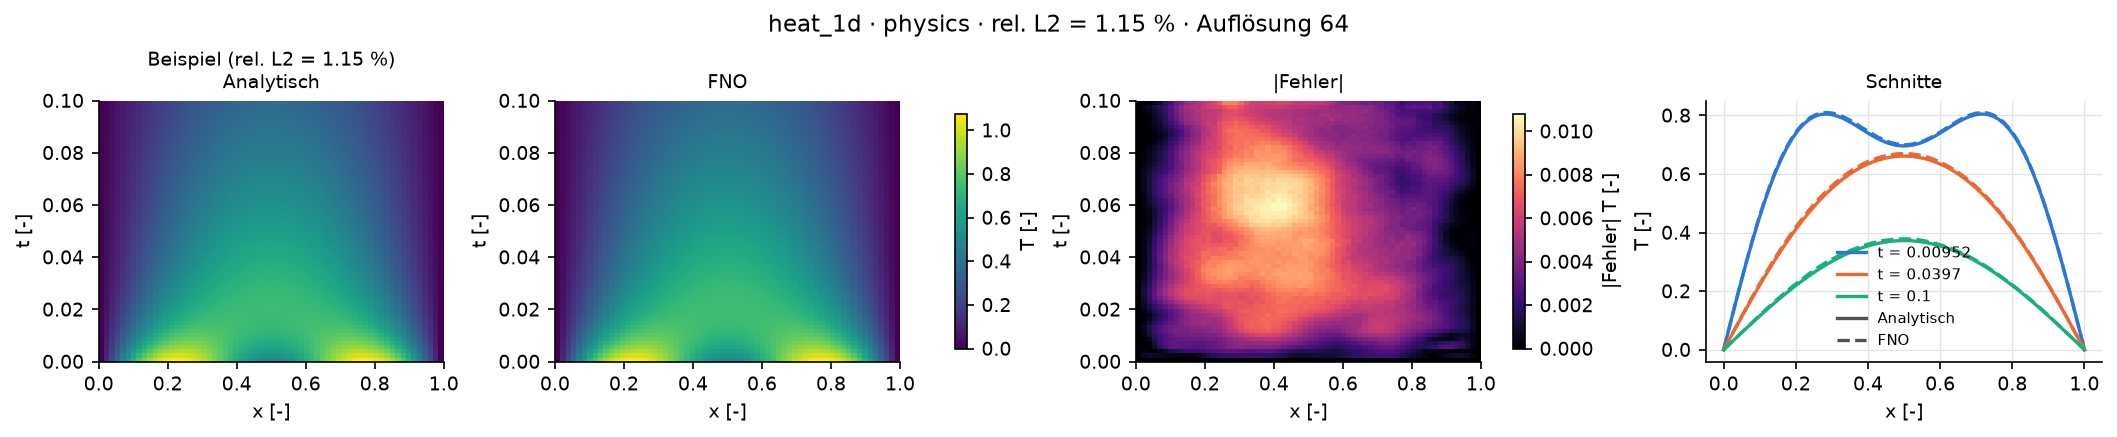

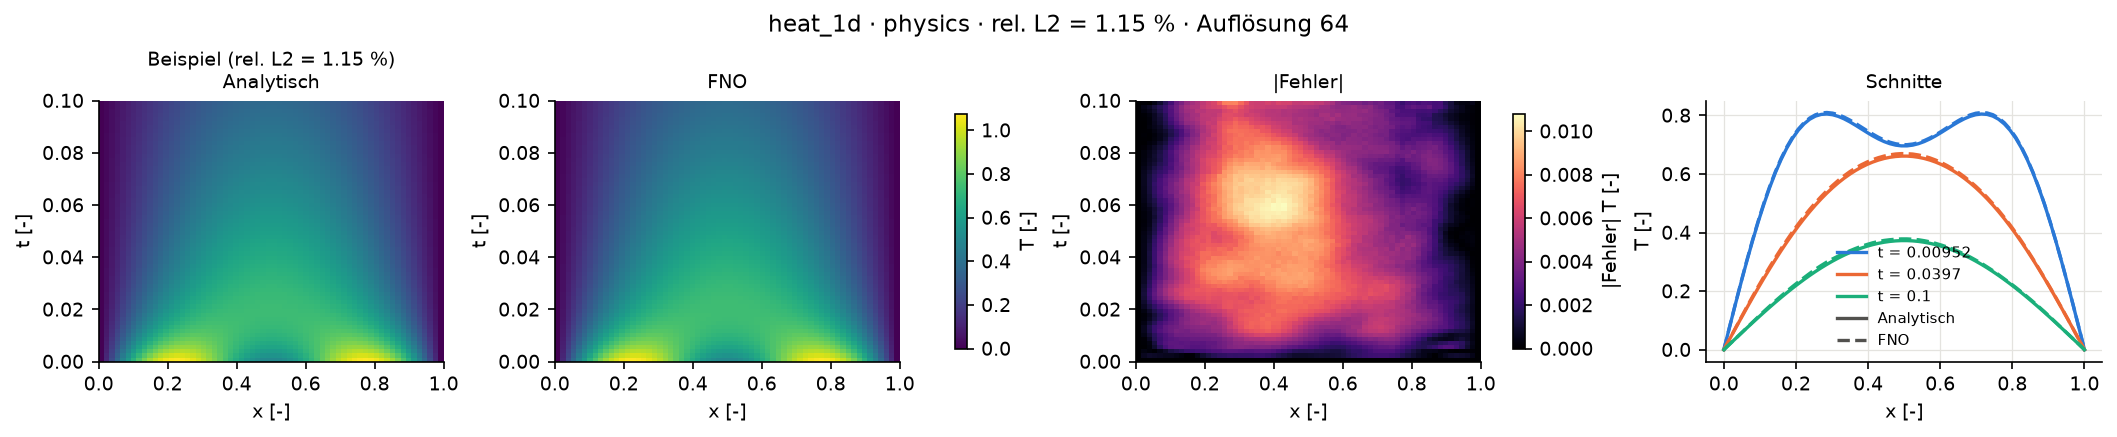

In [14]:
INPUTS = [1.0, 0.0, 0.5, 0.0, 0.0]
RESOLUTION = None

prediction = predict_one(run, INPUTS, RESOLUTION)
print("rel. L2 ", {k: f"{100 * v:.3f} %" for k, v in prediction.rel_l2.items()})
print("bc error", {k: f"{100 * v:.3f} %" for k, v in prediction.bc_error.items()})
for message in prediction.extrapolation:
    print("EXTRAPOLATION:", message)
plot_prediction(run.problem, prediction, run.mode)  # last expression: shown inline

## Save

Writes `<run_dir>/predictions/<name>/` with `inputs.json`, `result.json`, `prediction.pt` and `solution.png`.

In [10]:
# save_prediction(run, prediction, "my_case")

# Try it: one block per benchmark

Run the helper cell once, then any block on its own, or everything with "Run All". Each block has:

- `CASES`: named inputs, in the layout given above the block. Change them or add your own. Cases called "outside" lie beyond the trained range on purpose.
- `compare_variants`: rel. L2 of the main variable for every trained variant and every case, so you see at a glance which network handles what.
- `try_cases`: one variant in detail, with errors per variable and the plots. Change `mode` (`physics`, `data`, `hybrid`), `output_param` (`constrained`, `soft`, `unscaled`, `direct`) or set `resolution=128`; a combination that was not trained lists what exists.

`SHOW_PLOTS = False` in the helper cell leaves only the tables. The cases are only examples: the trained ranges and the errors are computed against the analytical solution of the benchmark.

In [15]:
import warnings

import matplotlib.pyplot as plt
from IPython.display import display

from pino.problems import problem_class
from pino.visualization import plot_deformation, plot_stress, run_title

SHOW_PLOTS = True  # False: only the tables, much faster and a much smaller notebook file
RESOLUTION_DEFAULT = None  # None = test grid of the run; a number or a list per axis

_runs = {}


def cached_run(run_dir):
    """load_run once per run, so that running a block again is fast."""
    if run_dir not in _runs:
        _runs[run_dir] = load_run(run_dir)
    return _runs[run_dir]


def predict_quiet(run, values, resolution):
    """predict_one without its warning: the extrapolation is printed in the tables instead."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return predict_one(run, values, resolution)


def trained_variants(benchmark, family):
    """Sorted (output_param, mode) of the finished runs of one input family."""
    found = set()
    for path in (OUTPUTS / benchmark).glob(f"{family}-*/*/*/metrics.json"):
        m = json.loads(path.read_text())
        if m.get("inputs", family) == family:
            found.add((m.get("output_param", "constrained"), m["mode"]))
    return sorted(found)


def compare_variants(benchmark, cases, family=None, resolution=RESOLUTION_DEFAULT):
    """Table: rel. L2 of the main variable for every trained variant and every case. * = extrapolation."""
    family = family or problem_class(benchmark).default_inputs()
    variants = trained_variants(benchmark, family)
    if not variants:
        print(f"No finished run of {benchmark} with inputs {family}.")
        return
    names = list(cases)
    for i, name in enumerate(names, 1):
        print(f"  case {i}: {name}")
    print(f"{'':28s}" + "".join(f"{'case ' + str(i):>11s}" for i in range(1, len(names) + 1)))
    for output_param, mode in variants:
        run = cached_run(find_run(benchmark, mode, output_param, family, outputs=OUTPUTS))
        cells = ""
        for name in names:
            p = predict_quiet(run, cases[name], resolution)
            mark = "*" if p.extrapolation else " "
            cells += f"{100 * p.rel_l2[run.problem.main_variable]:>9.2f}%{mark}"
        print(f"{output_param + ' ' + mode:28s}" + cells)


def try_cases(benchmark, cases, mode="physics", output_param="constrained", family=None,
              resolution=RESOLUTION_DEFAULT, seed=None):
    """One variant in detail: errors per variable, the trained ranges and the plots of every case."""
    family = family or problem_class(benchmark).default_inputs()
    try:
        run_dir = find_run(benchmark, mode, output_param, family, seed, outputs=OUTPUTS)
    except FileNotFoundError as error:
        print(error)
        return
    run = cached_run(run_dir)
    problem = run.problem
    low, high = problem.input_ranges()
    print(run_dir.relative_to(ROOT))
    print("trained input ranges, low ", [round(v, 3) for v in low.flatten().tolist()])
    print("                      high", [round(v, 3) for v in high.flatten().tolist()])
    for name, values in cases.items():
        p = predict_quiet(run, values, resolution)
        print(f"\n{name}")
        print("  rel. L2 ", {k: f"{100 * v:.3f} %" for k, v in p.rel_l2.items()})
        print("  bc error", {k: f"{100 * v:.3f} %" for k, v in p.bc_error.items()})
        for message in p.extrapolation:
            print("  EXTRAPOLATION:", message)
        if not SHOW_PLOTS:
            continue
        figures = [plot_prediction(problem, p, run.mode)]
        if problem.mechanics_plots:
            result, title = p.as_result(problem), run_title(problem, run.mode, p.rel_l2[problem.main_variable])
            figures += [plot_deformation(problem, result, title, None), plot_stress(problem, result, title, None)]
        for figure in figures:
            display(figure)
            plt.close(figure)

## Thermal

### `heat_1d`, inputs `sine`

T₀ = Σ bₙ sin(nπx). Input: `[b1, b2, b3, b4, b5]`, trained bₙ ∈ [−1, 1].

  case 1: first mode only
  case 2: highest mode only
  case 3: two modes
  case 4: all modes at the limit
  case 5: outside: amplitude 2
                                 case 1     case 2     case 3     case 4     case 5
constrained data                 0.30%      1.24%      0.34%      1.76%      1.11%*
constrained hybrid               0.20%      1.33%      0.22%      1.72%      0.47%*
constrained physics              1.50%      1.87%      1.15%      2.35%      1.04%*
soft data                        0.17%      0.69%      0.18%      0.76%      0.79%*
soft hybrid                      0.10%      1.08%      0.11%      0.63%      0.86%*
soft physics                     0.32%      2.37%      0.30%      2.78%      4.60%*
outputs/heat_1d/sine-constrained/physics/2026-11-06_15-19-22
trained input ranges, low  [-1.0, -1.0, -1.0, -1.0, -1.0]
                      high [1.0, 1.0, 1.0, 1.0, 1.0]

first mode only
  rel. L2  {'T': '1.502 %'}
  bc error {'T': '0.000 %'}


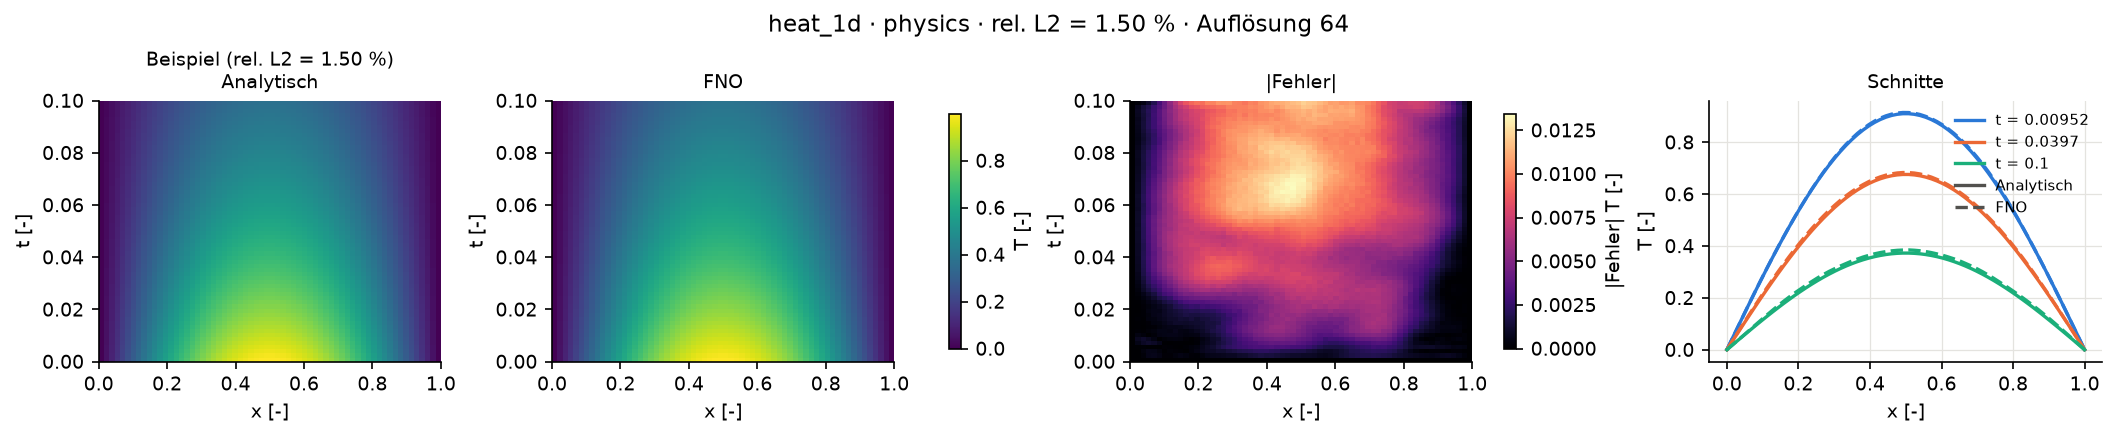


highest mode only
  rel. L2  {'T': '1.867 %'}
  bc error {'T': '0.000 %'}


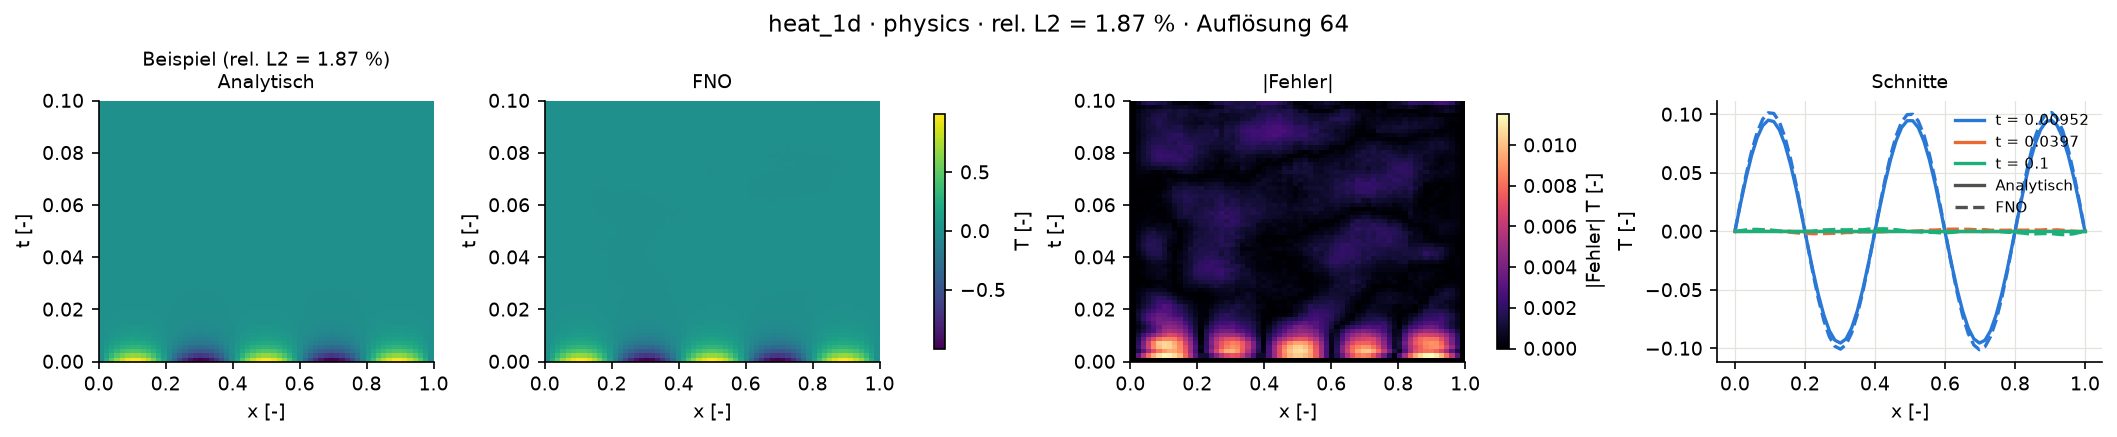


two modes
  rel. L2  {'T': '1.151 %'}
  bc error {'T': '0.000 %'}


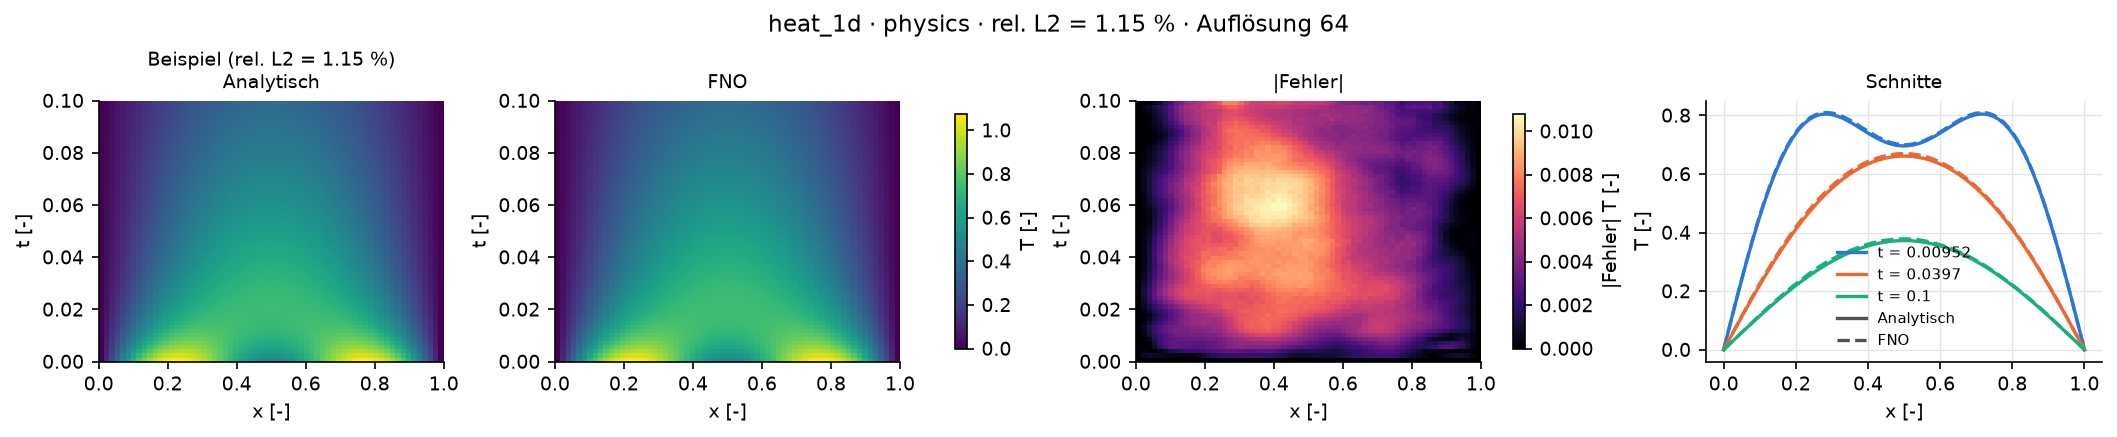


all modes at the limit
  rel. L2  {'T': '2.350 %'}
  bc error {'T': '0.000 %'}


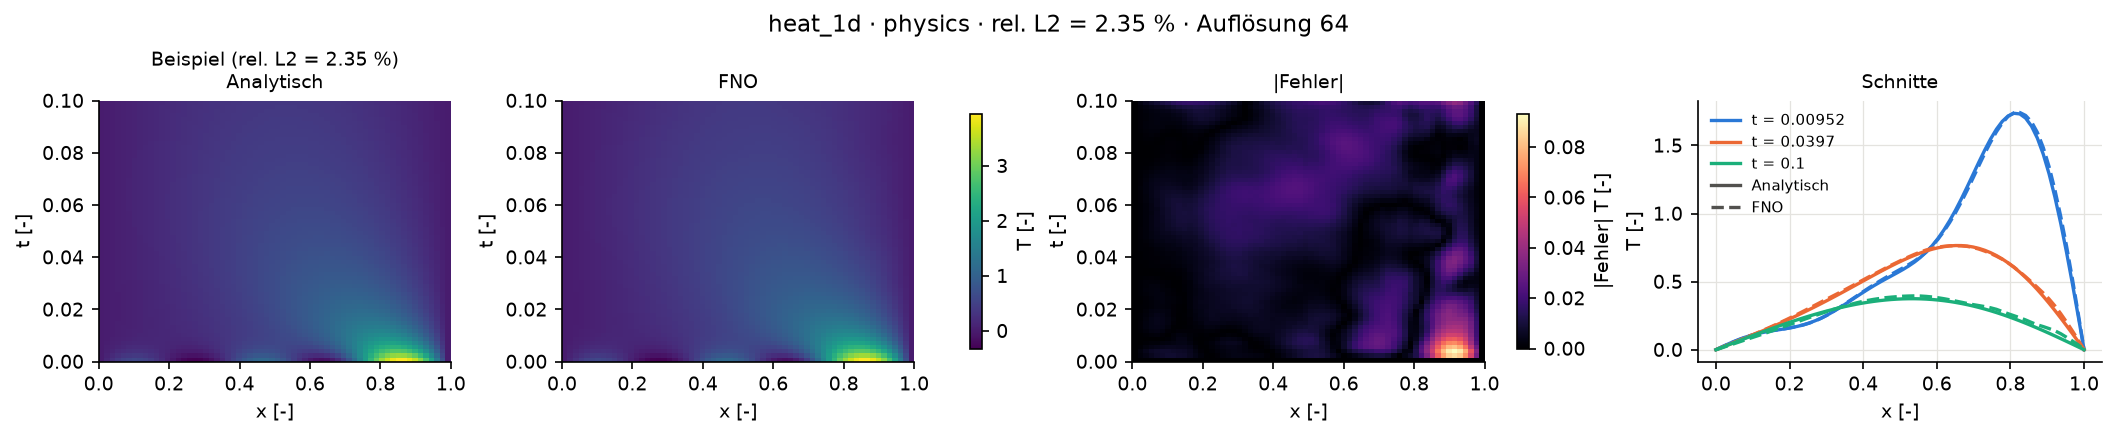


outside: amplitude 2
  rel. L2  {'T': '1.043 %'}
  bc error {'T': '0.000 %'}
  EXTRAPOLATION: input[0] = 2 outside the trained range [-0.9995, 1]


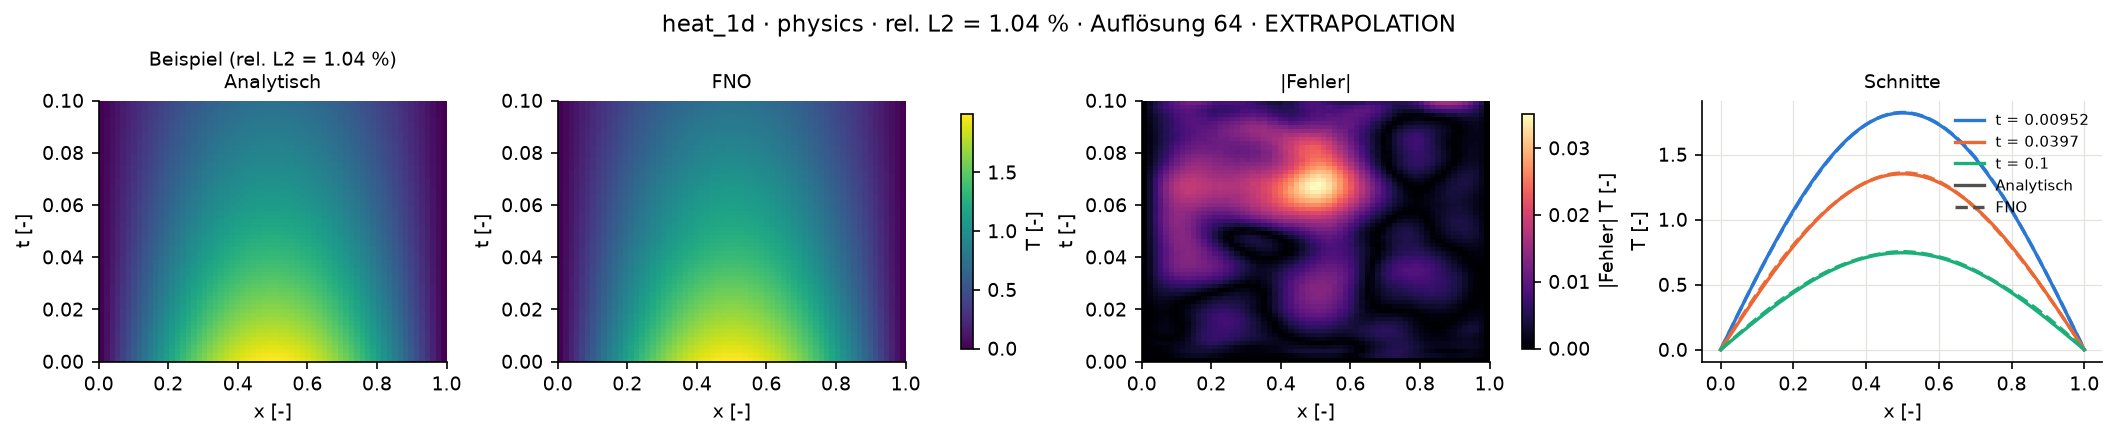

In [5]:
CASES = {
    "first mode only": [1.0, 0.0, 0.0, 0.0, 0.0],
    "highest mode only": [0.0, 0.0, 0.0, 0.0, 1.0],
    "two modes": [1.0, 0.0, 0.5, 0.0, 0.0],
    "all modes at the limit": [1.0, -1.0, 1.0, -1.0, 1.0],
    "outside: amplitude 2": [2.0, 0.0, 0.0, 0.0, 0.0],
}
compare_variants("heat_1d", CASES)
try_cases("heat_1d", CASES, mode="physics", output_param="constrained")

### `heat_1d`, inputs `sine_ramp`

As `sine`, plus edge values linear in time, T(0, t) = α_L + β_L t, T(1, t) = α_R + β_R t. Input: `[b1..b5, aL, bL, aR, bR]`, trained α ∈ [−1, 1], β ∈ [−10, 10].

In [ ]:
CASES = {
    "modes only, cold edges": [1.0, 0.0, 0.5, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    "constant edges, no modes": [0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, -1.0, 0.0],
    "opposite ramps": [0.5, 0.0, 0.0, 0.0, 0.0, 0.0, 10.0, 0.0, -10.0],
    "everything at once": [1.0, -0.5, 0.5, 0.0, 0.0, 0.5, -5.0, -0.5, 5.0],
    "outside: ramp 20": [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 20.0, 0.0, 0.0],
}
compare_variants("heat_1d", CASES, family="sine_ramp")
try_cases("heat_1d", CASES, mode="physics", output_param="constrained", family="sine_ramp")

### `heat_2d`

T₀ = Σ b_mn sin(mπx) sin(nπy). Input: 3 × 3 matrix `b`, trained b_mn ∈ [−1, 1]. 3D FNO, slower than the others.

In [ ]:
CASES = {
    "mode (1, 1)": [[1, 0, 0], [0, 0, 0], [0, 0, 0]],
    "mode (3, 3), fastest decay": [[0, 0, 0], [0, 0, 0], [0, 0, 1]],
    "modes (1, 2) and (2, 1)": [[0, 1, 0], [-1, 0, 0], [0, 0, 0]],
    "checkerboard at the limit": [[1, -1, 1], [-1, 1, -1], [1, -1, 1]],
    "outside: amplitude 2": [[2, 0, 0], [0, 0, 0], [0, 0, 0]],
}
compare_variants("heat_2d", CASES)
try_cases("heat_2d", CASES, mode="physics", output_param="constrained")

## Mechanics

### `beam_1d`, inputs `linear`

q(x) = q₀ + q₁x. Input: `[q0, q1, EI]`, trained q ∈ [0, 1], EI ∈ [0.5, 2].

In [ ]:
CASES = {
    "uniform load": [1.0, 0.0, 1.0],
    "triangular load": [0.0, 1.0, 1.0],
    "soft beam, full load": [1.0, 1.0, 0.5],
    "stiff beam": [0.5, 0.5, 2.0],
    "outside: EI = 0.2": [1.0, 0.0, 0.2],
}
compare_variants("beam_1d", CASES)
try_cases("beam_1d", CASES, mode="physics", output_param="constrained")

### `beam_1d`, inputs `sine`

q(x) = Σ qₙ sin(nπx). Input: `[q1..q8, EI]`, trained qₙ ∈ [−1/n, 1/n], EI ∈ [0.5, 2].

In [ ]:
CASES = {
    "first mode": [1.0, 0, 0, 0, 0, 0, 0, 0, 1.0],
    "highest mode": [0, 0, 0, 0, 0, 0, 0, 0.125, 1.0],
    "alternating, all modes": [1.0, -0.5, 0.333, -0.25, 0.2, -0.167, 0.143, -0.125, 1.0],
    "soft beam": [0.5, 0.25, 0, 0, 0, 0, 0, 0, 0.5],
    "outside: q8 = 1": [0, 0, 0, 0, 0, 0, 0, 1.0, 1.0],
}
compare_variants("beam_1d", CASES, family="sine")
try_cases("beam_1d", CASES, mode="physics", output_param="constrained", family="sine")

### `elastic_block_2d`

Load from above, p(x) = p₀ + Σ pₙ cos(nπx). Input: `[p0, p1..p6, nu]`, trained p₀ ∈ [0.5, 1], pₙ ∈ [−0.5/n, 0.5/n], ν ∈ [0.15, 0.35]. Also shows the deformed grid and the stresses. With the uniform load the exact u is 0, so its relative error means nothing.

  case 1: uniform load
  case 2: heavier on the left
  case 3: short wave n = 6
  case 4: all modes, nu = 0.15
  case 5: outside: nu = 0.45
  case 6: outside: load from below
                                 case 1     case 2     case 3     case 4     case 5     case 6
constrained data                 0.25%      0.34%      0.19%      0.75%      1.75%*    92.80%*
constrained hybrid               4.93%      3.52%      1.67%      4.53%      8.03%*   108.62%*
constrained physics              5.24%     12.61%      1.35%     10.74%     10.11%*   171.08%*
direct data                      0.18%      0.23%      0.16%      0.62%      1.56%*    65.82%*
soft data                        0.18%      0.20%      0.17%      0.62%      1.35%*    84.27%*
soft physics                    21.93%     14.28%      5.22%     25.13%     12.70%*   163.29%*
outputs/elastic_block_2d/cosine-constrained/data/2026-11-08_13-38-03
trained input ranges, low  [0.5, -0.5, -0.25, -0.167, -0.125, -0.1, -0.083, 0.15]
         

/home/imb-user/Documents/johannes/PINOBench/src/pino/visualization.py:480: RuntimeWarning: divide by zero encountered in scalar divide
  relative = np.linalg.norm(error) / np.linalg.norm(analytical)


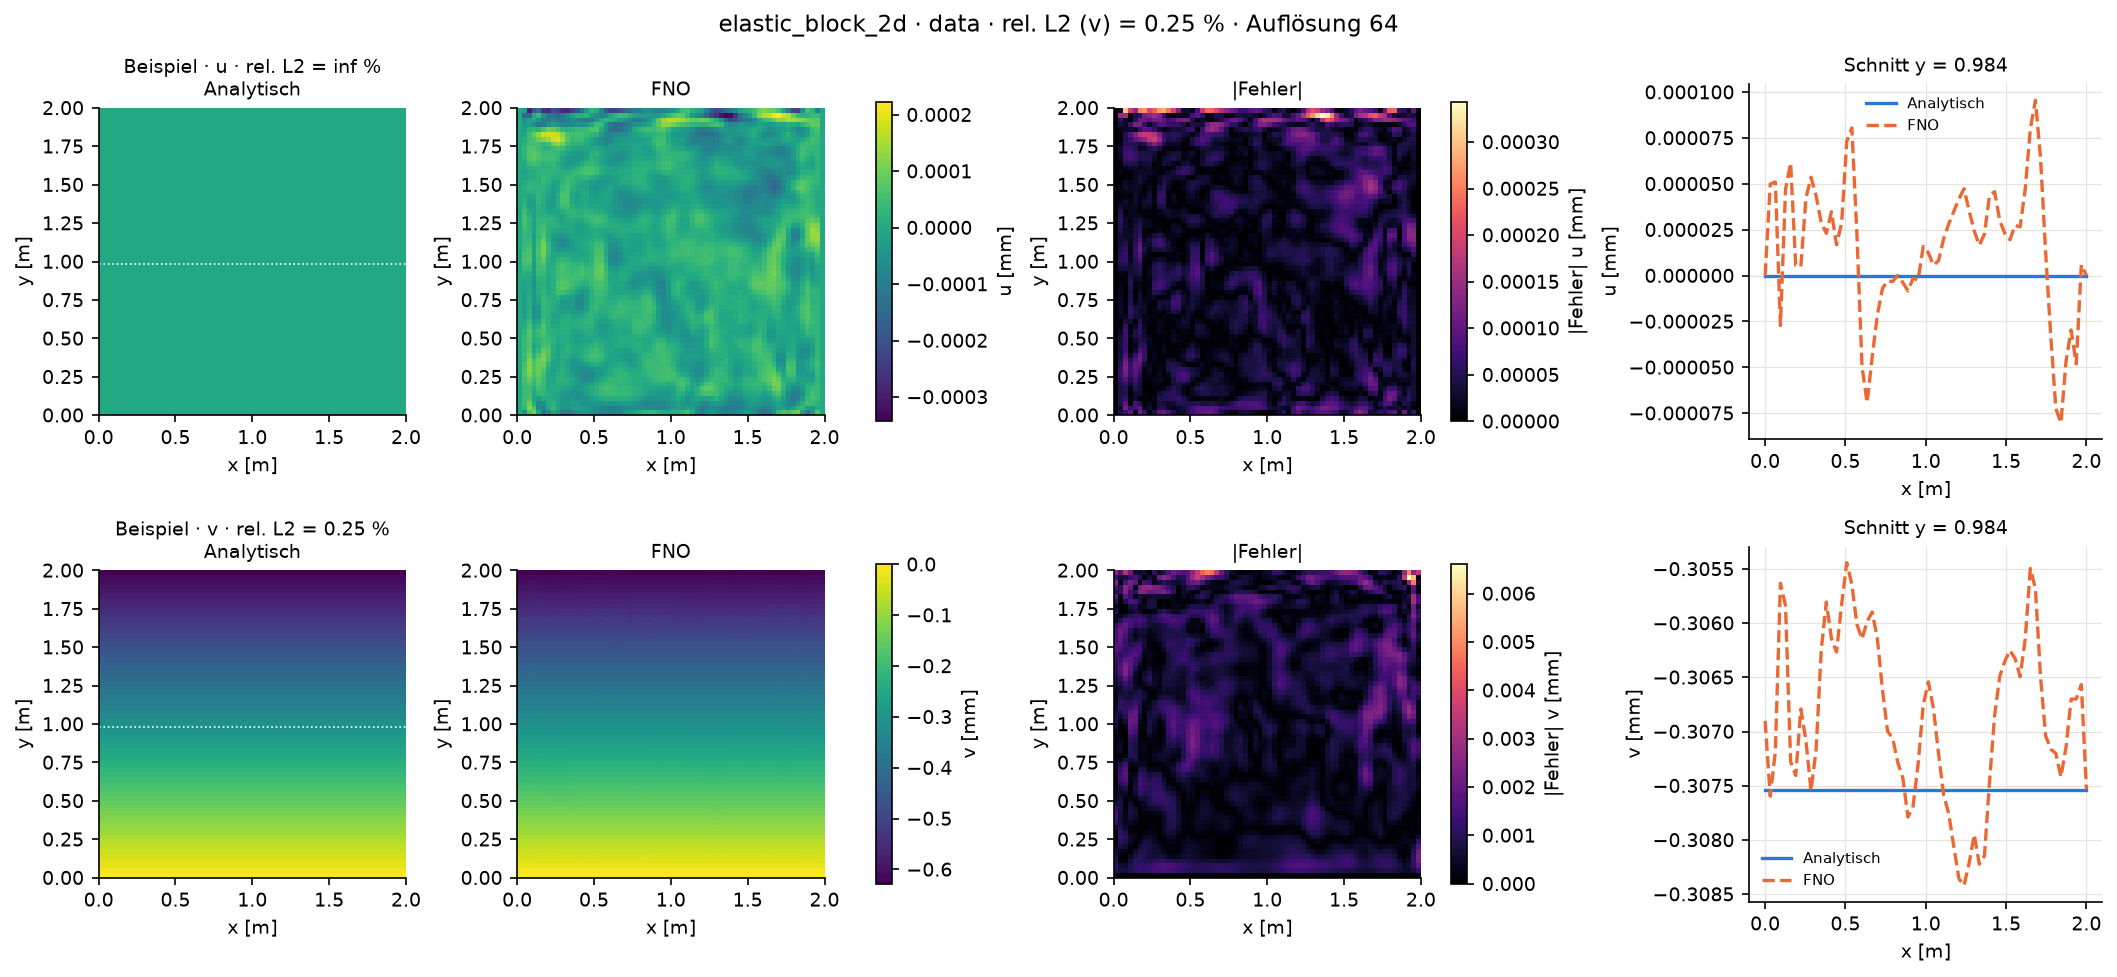

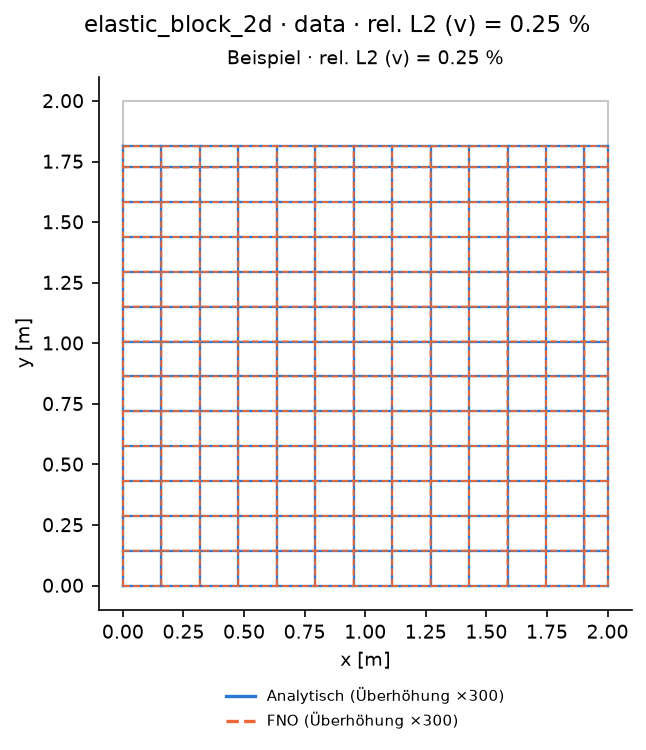

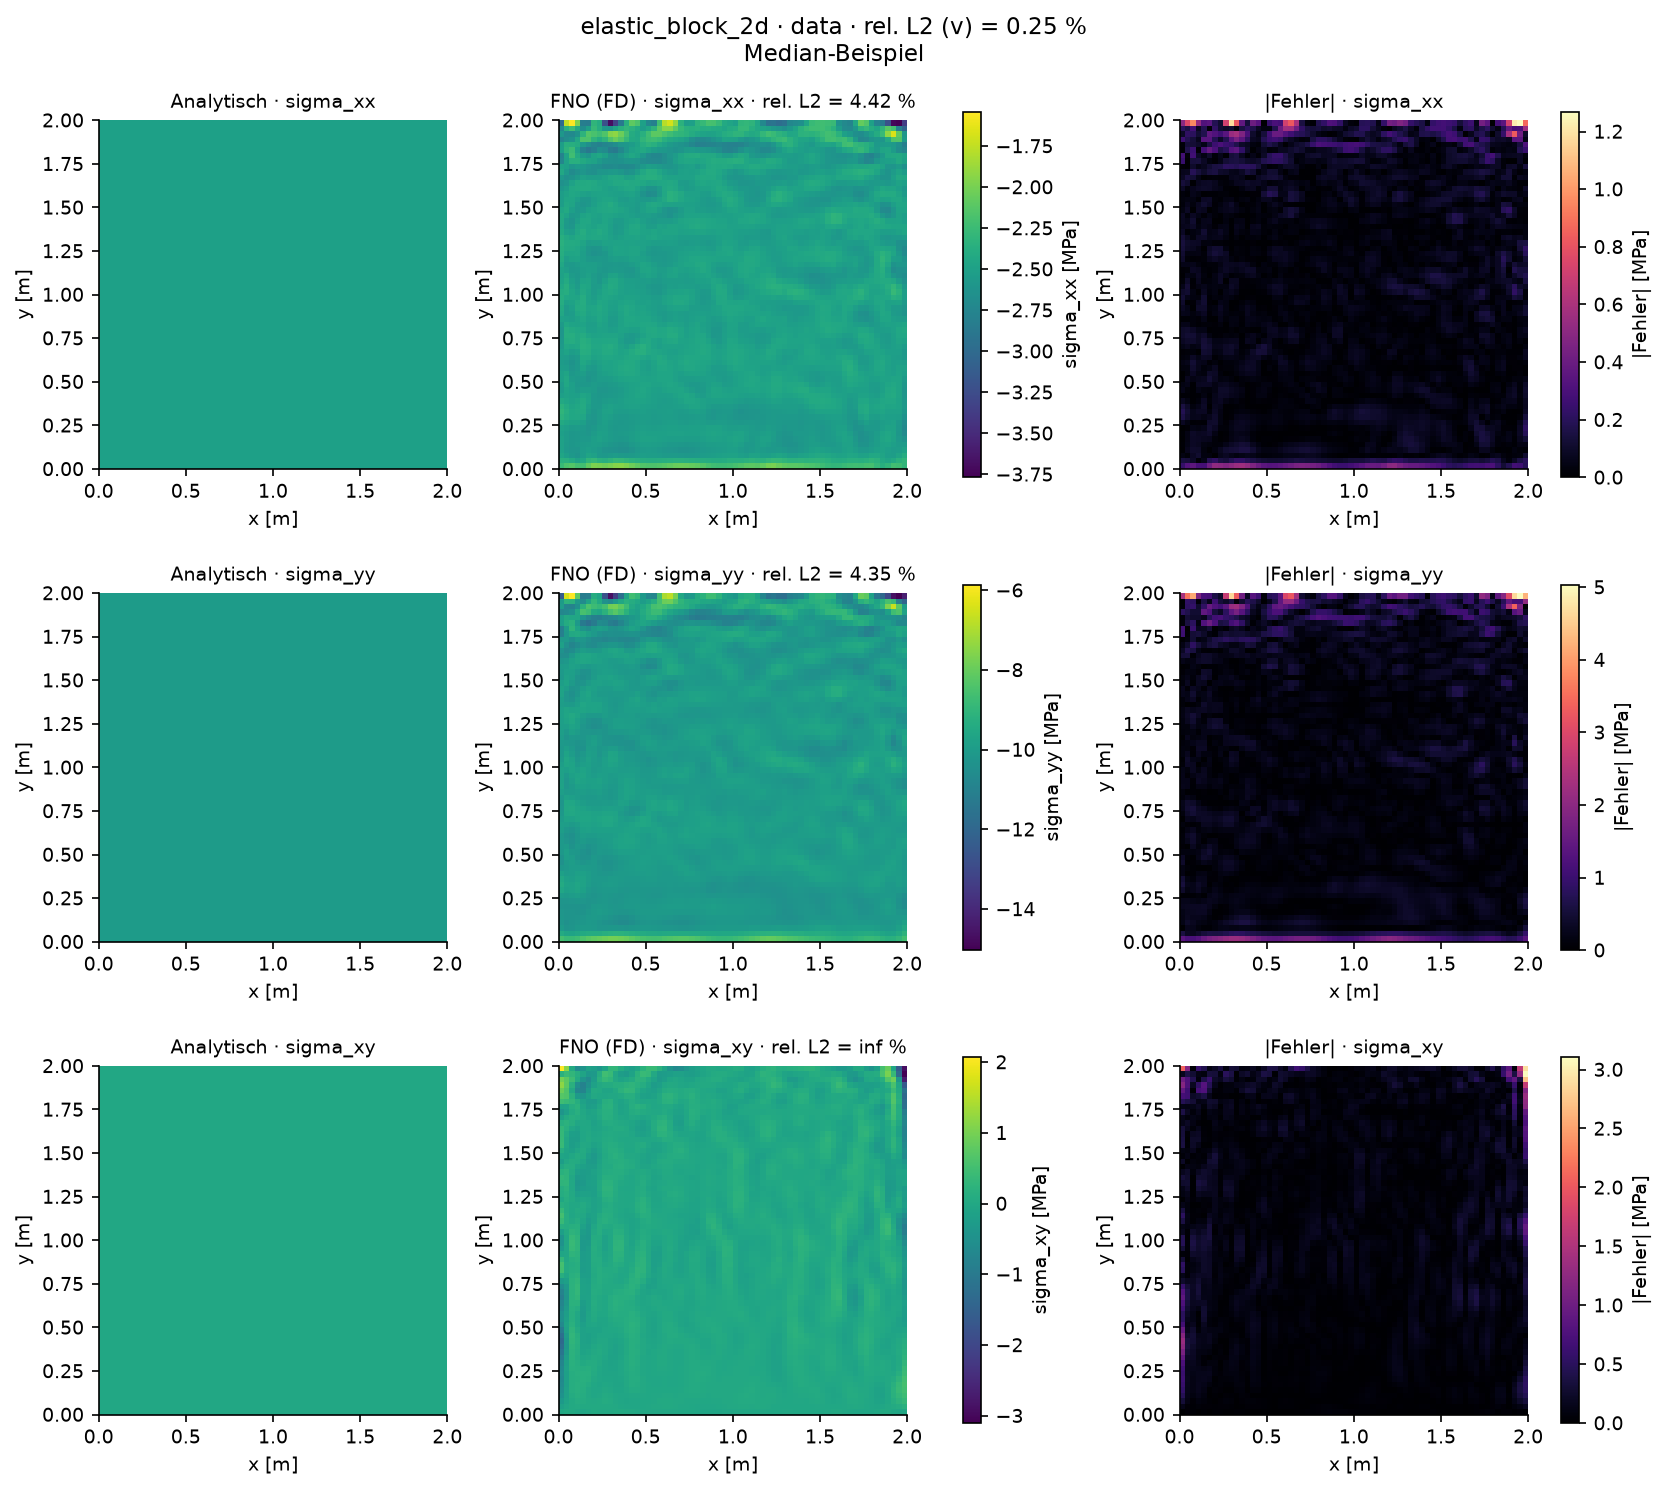


heavier on the left
  rel. L2  {'u': '0.255 %', 'v': '0.338 %'}
  bc error {'u': '0.000 %', 'v': '0.000 %'}


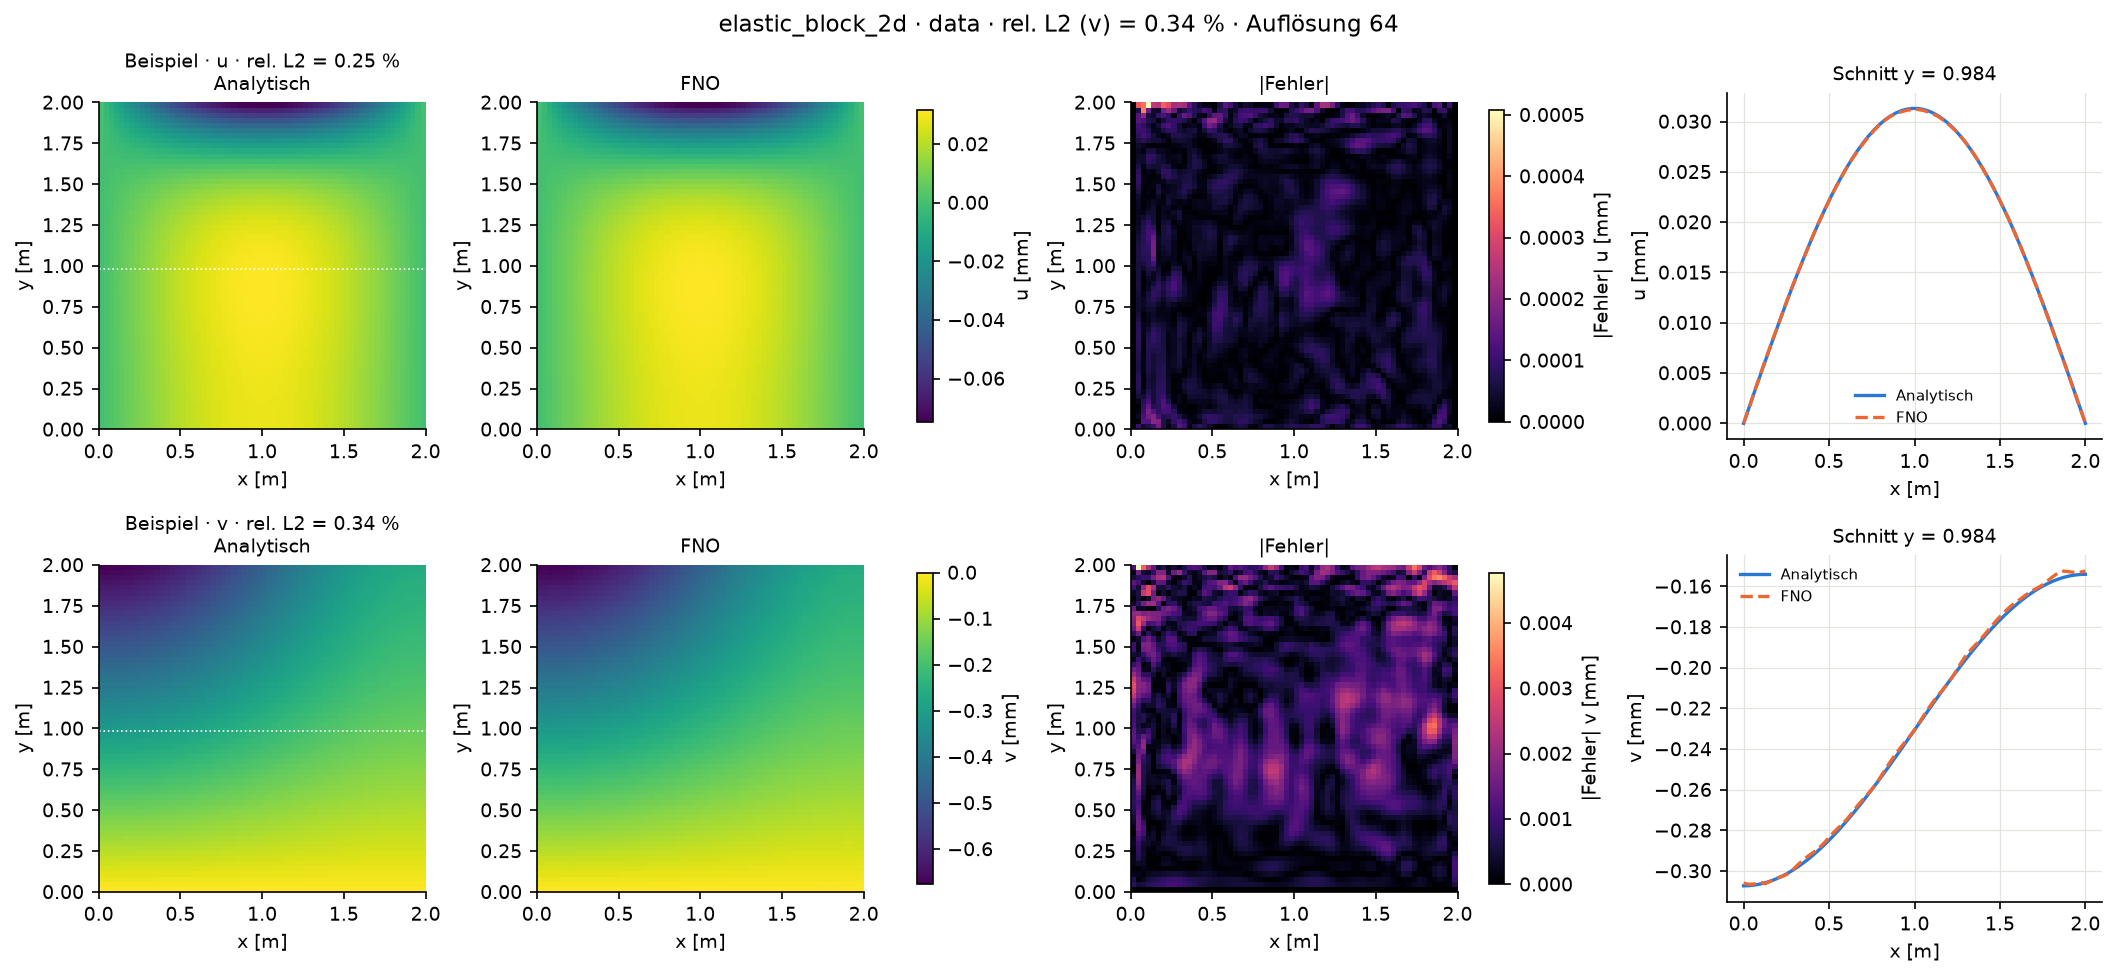

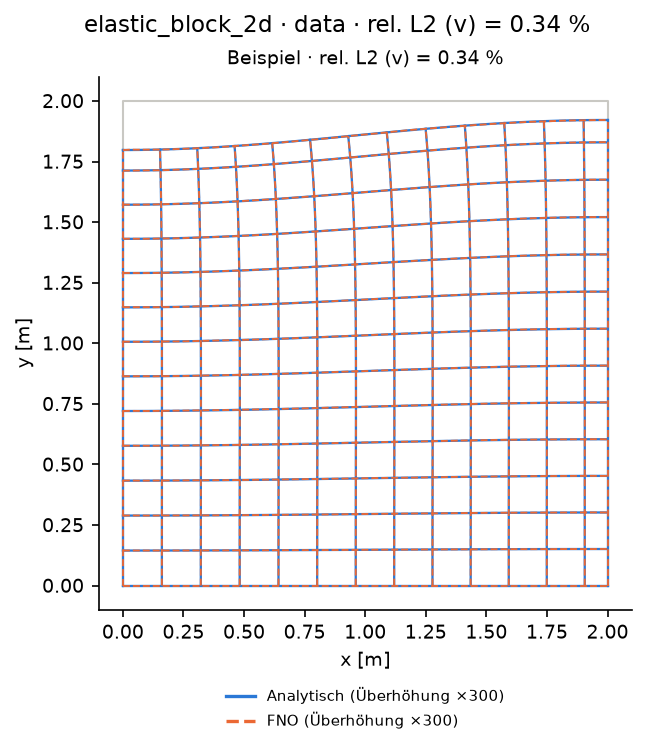

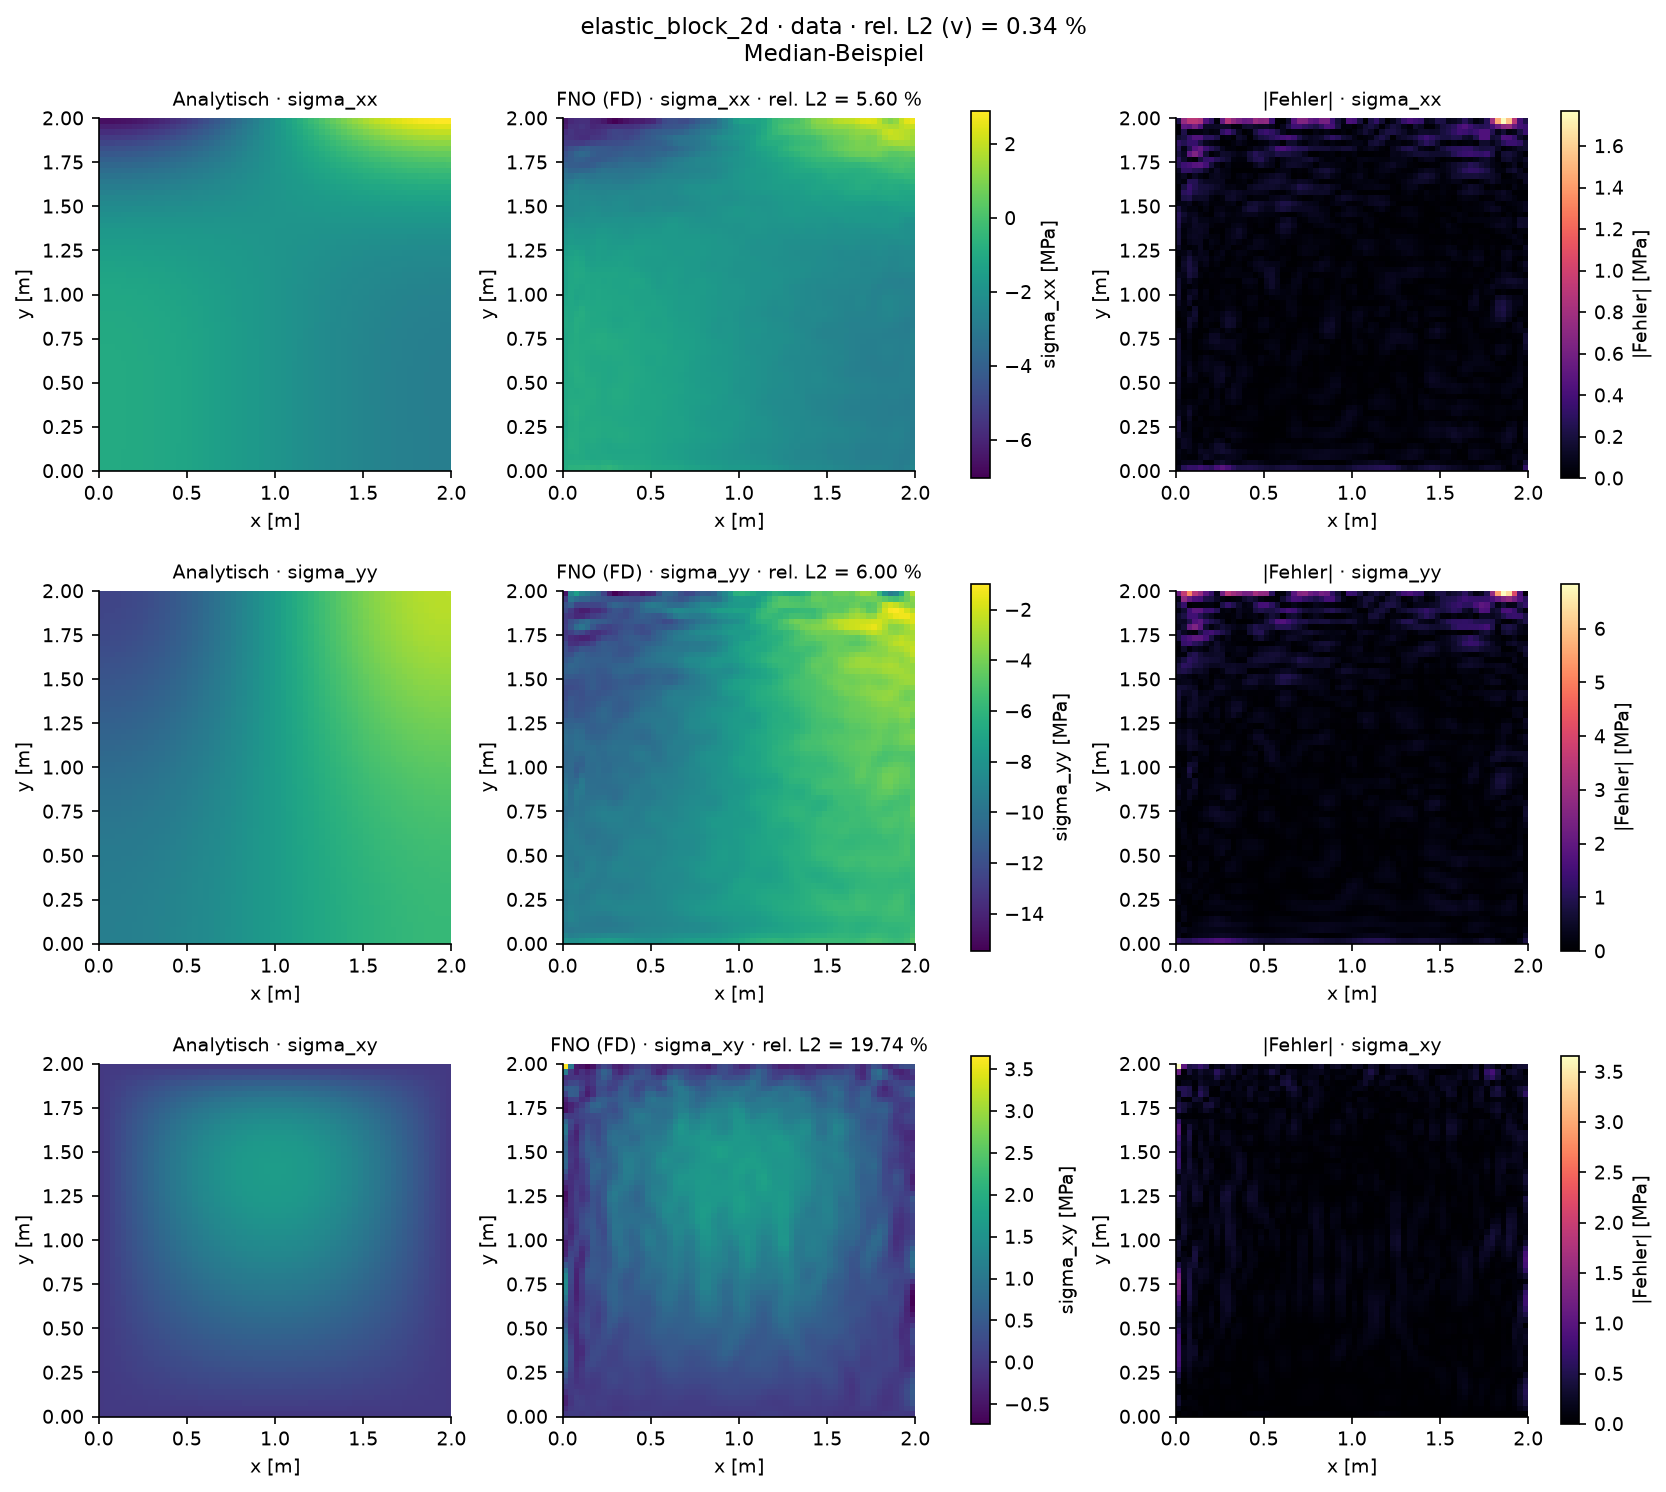


short wave n = 6
  rel. L2  {'u': '14.020 %', 'v': '0.191 %'}
  bc error {'u': '0.000 %', 'v': '0.000 %'}


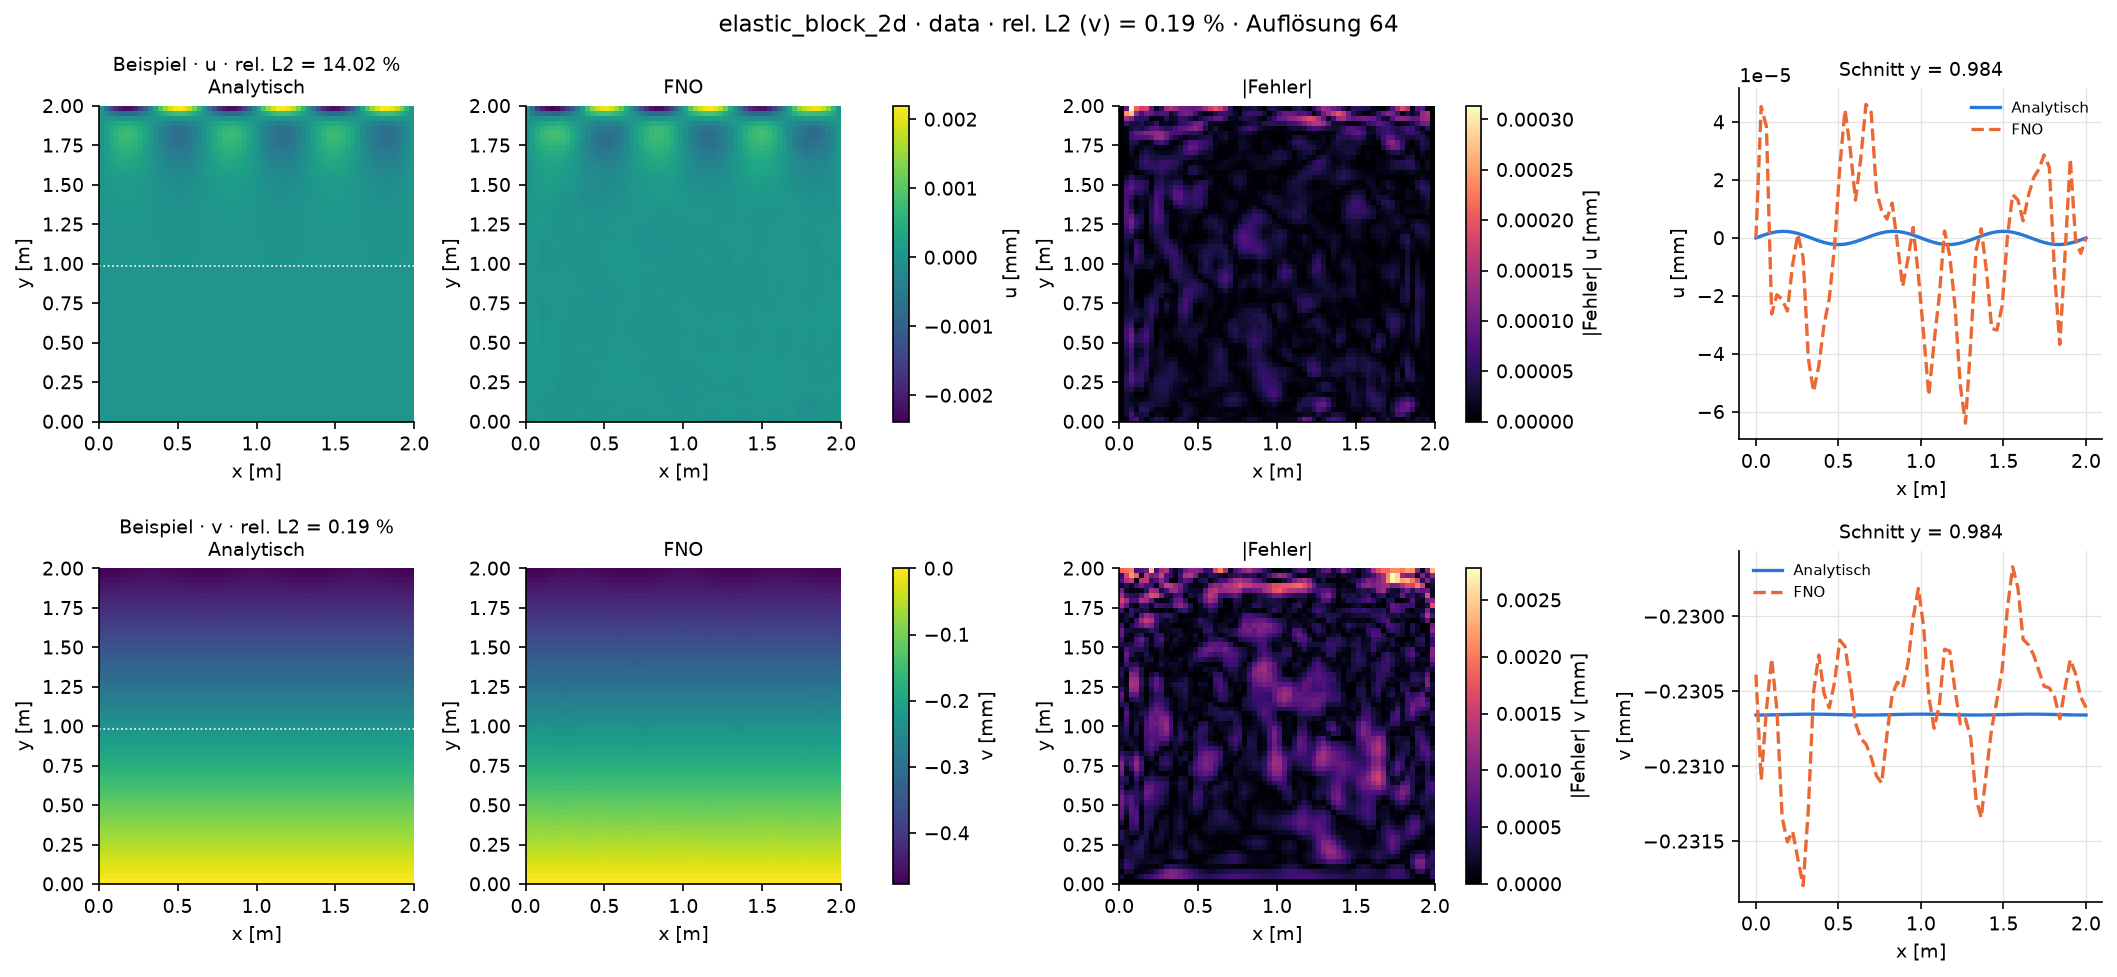

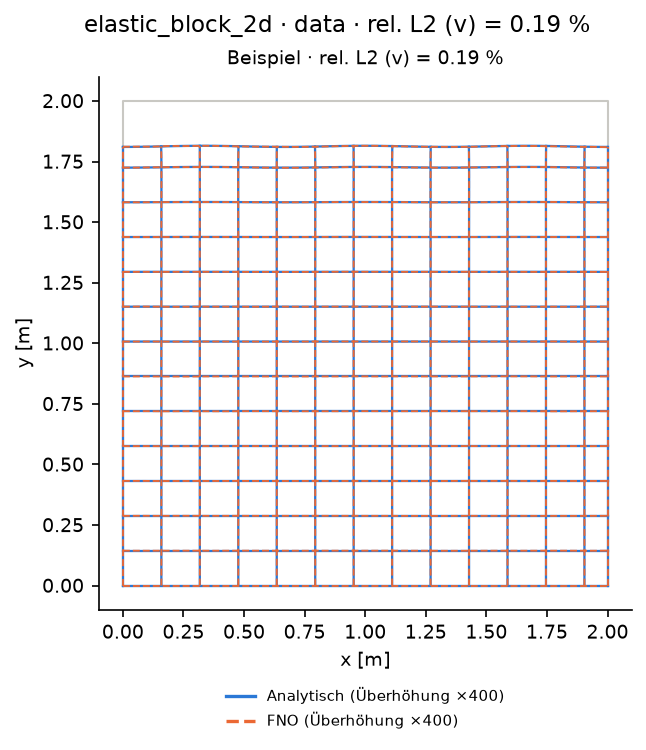

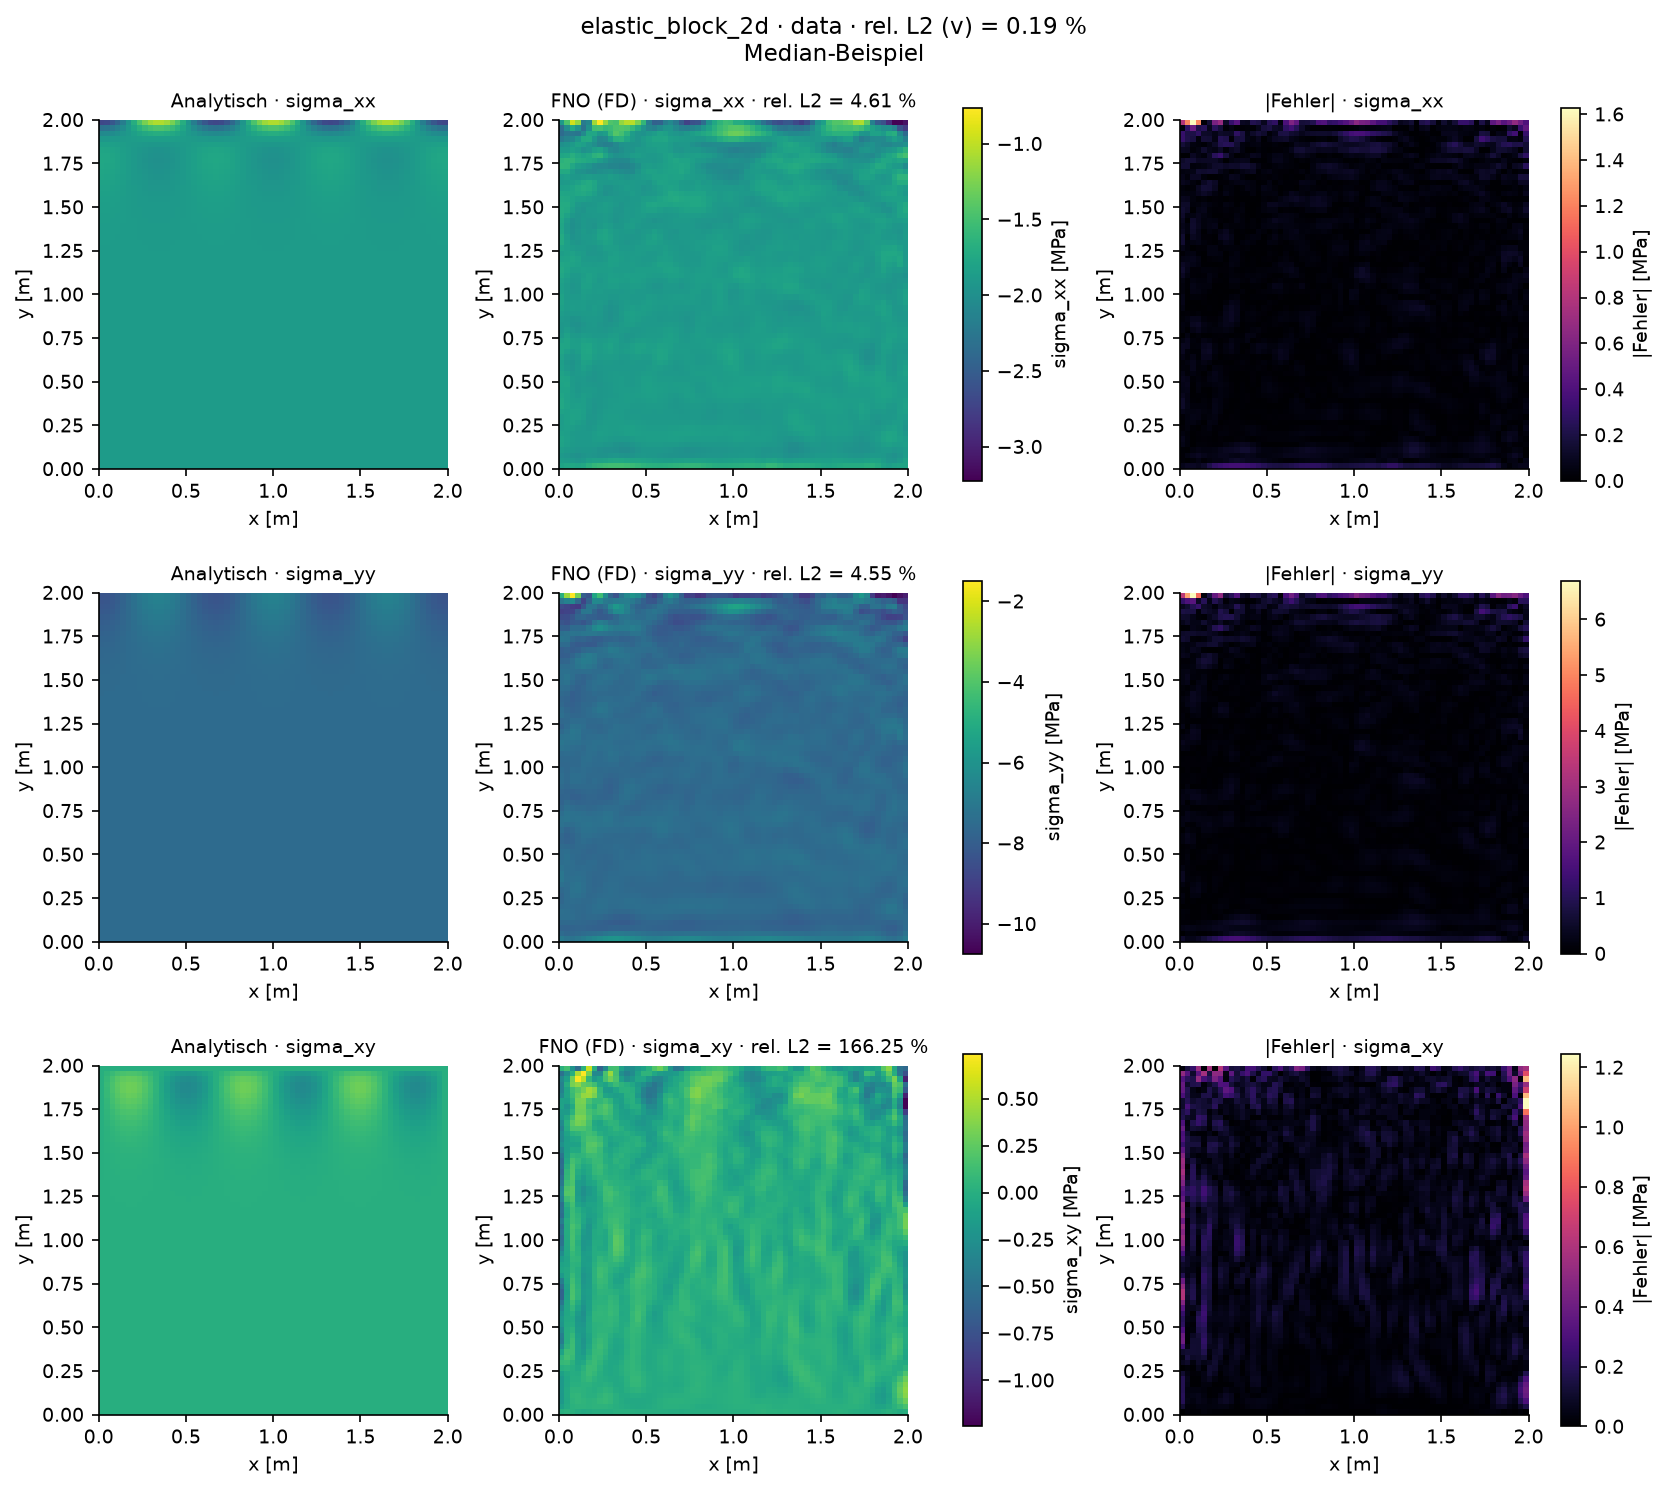


all modes, nu = 0.15
  rel. L2  {'u': '1.681 %', 'v': '0.752 %'}
  bc error {'u': '0.000 %', 'v': '0.000 %'}


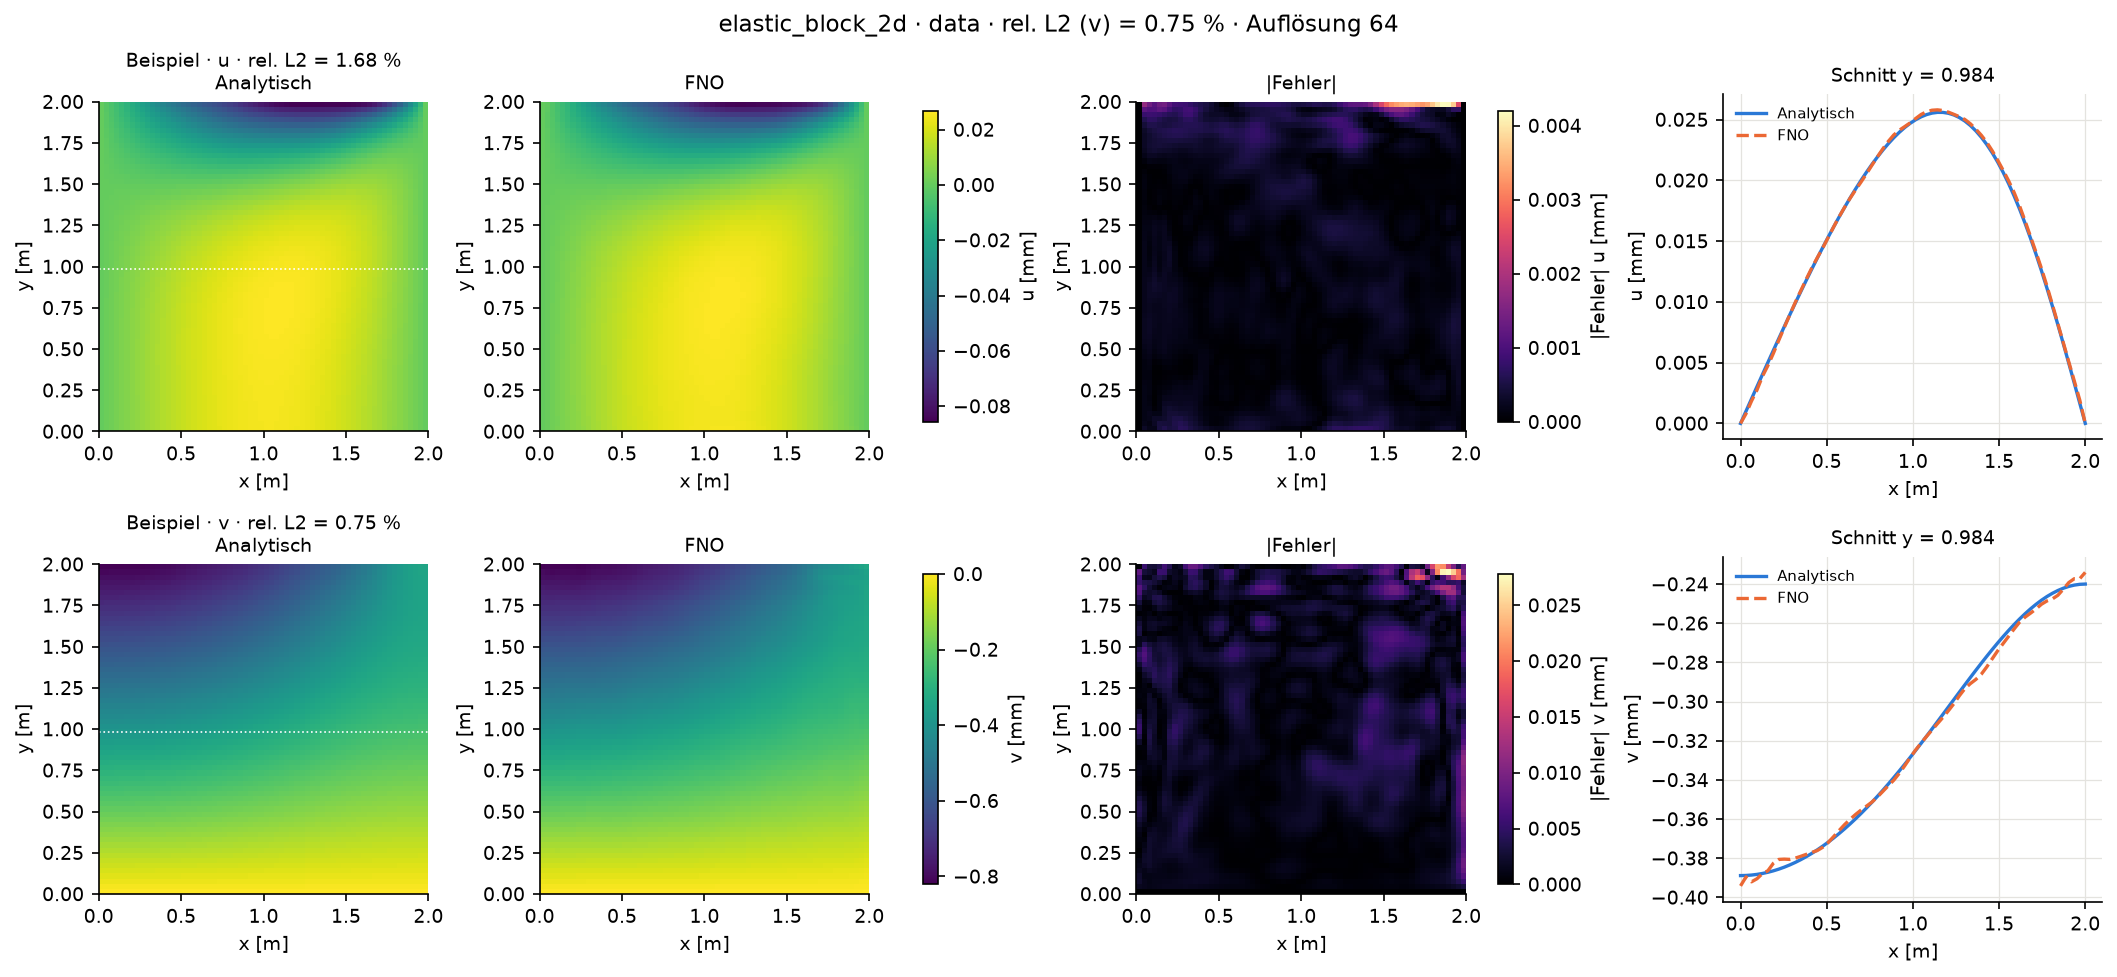

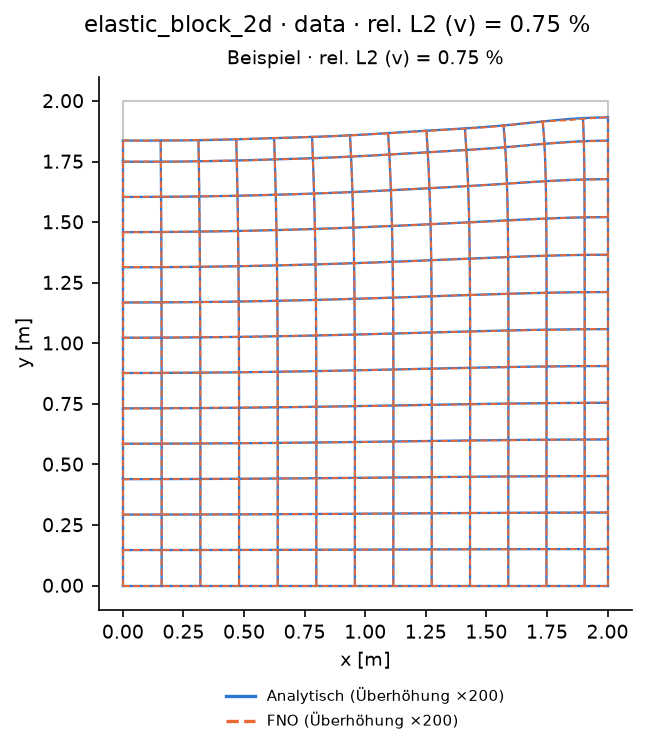

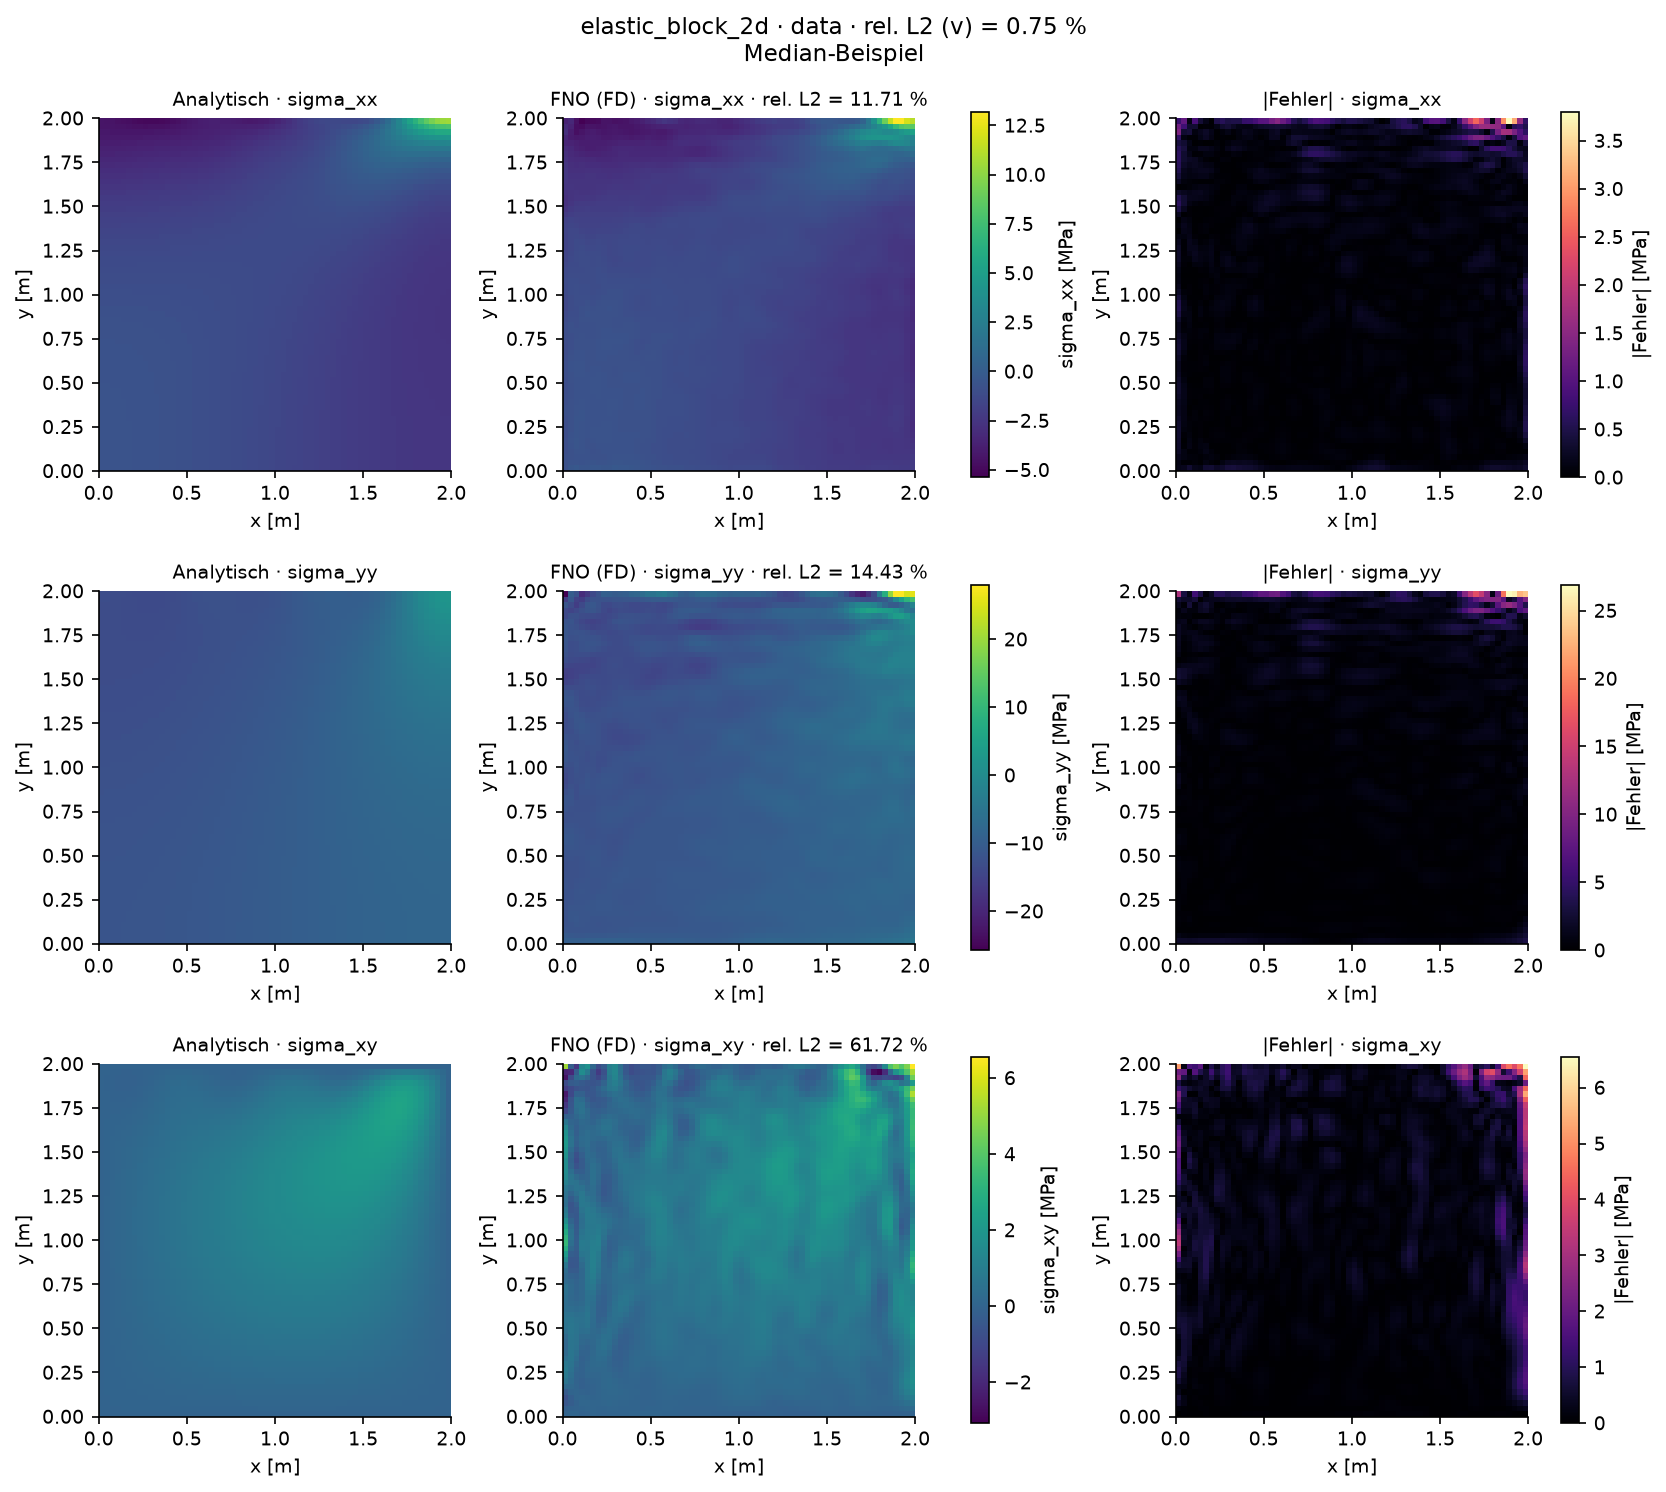


outside: nu = 0.45
  rel. L2  {'u': '3.884 %', 'v': '1.749 %'}
  bc error {'u': '0.000 %', 'v': '0.000 %'}
  EXTRAPOLATION: input[7] = 0.45 outside the trained range [0.15, 0.35]


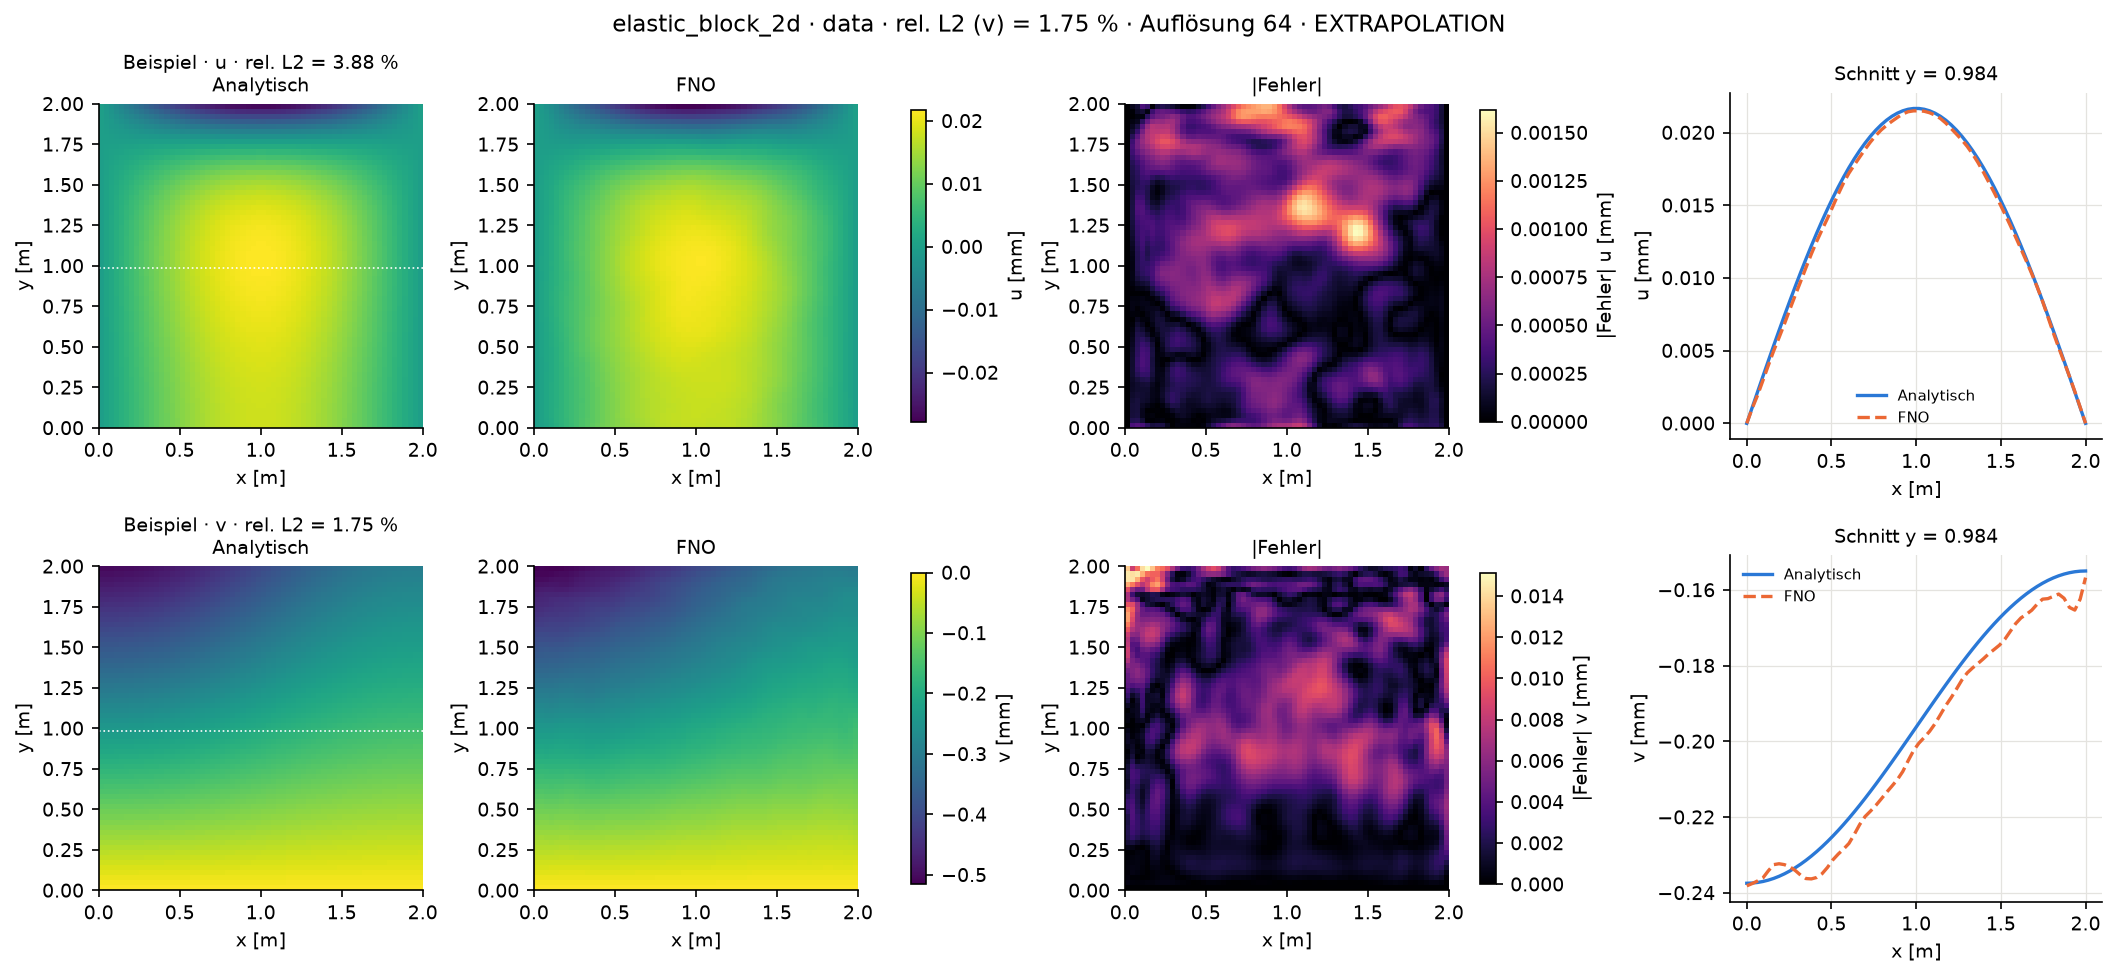

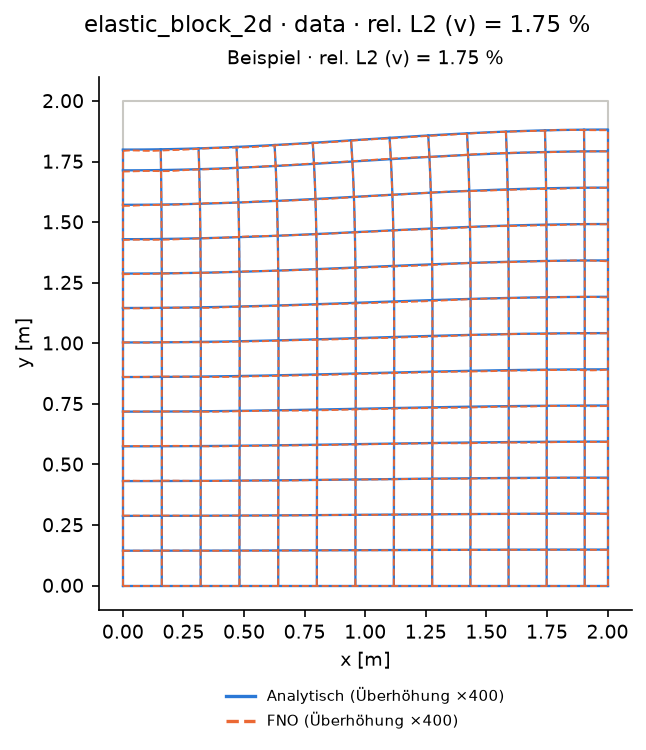

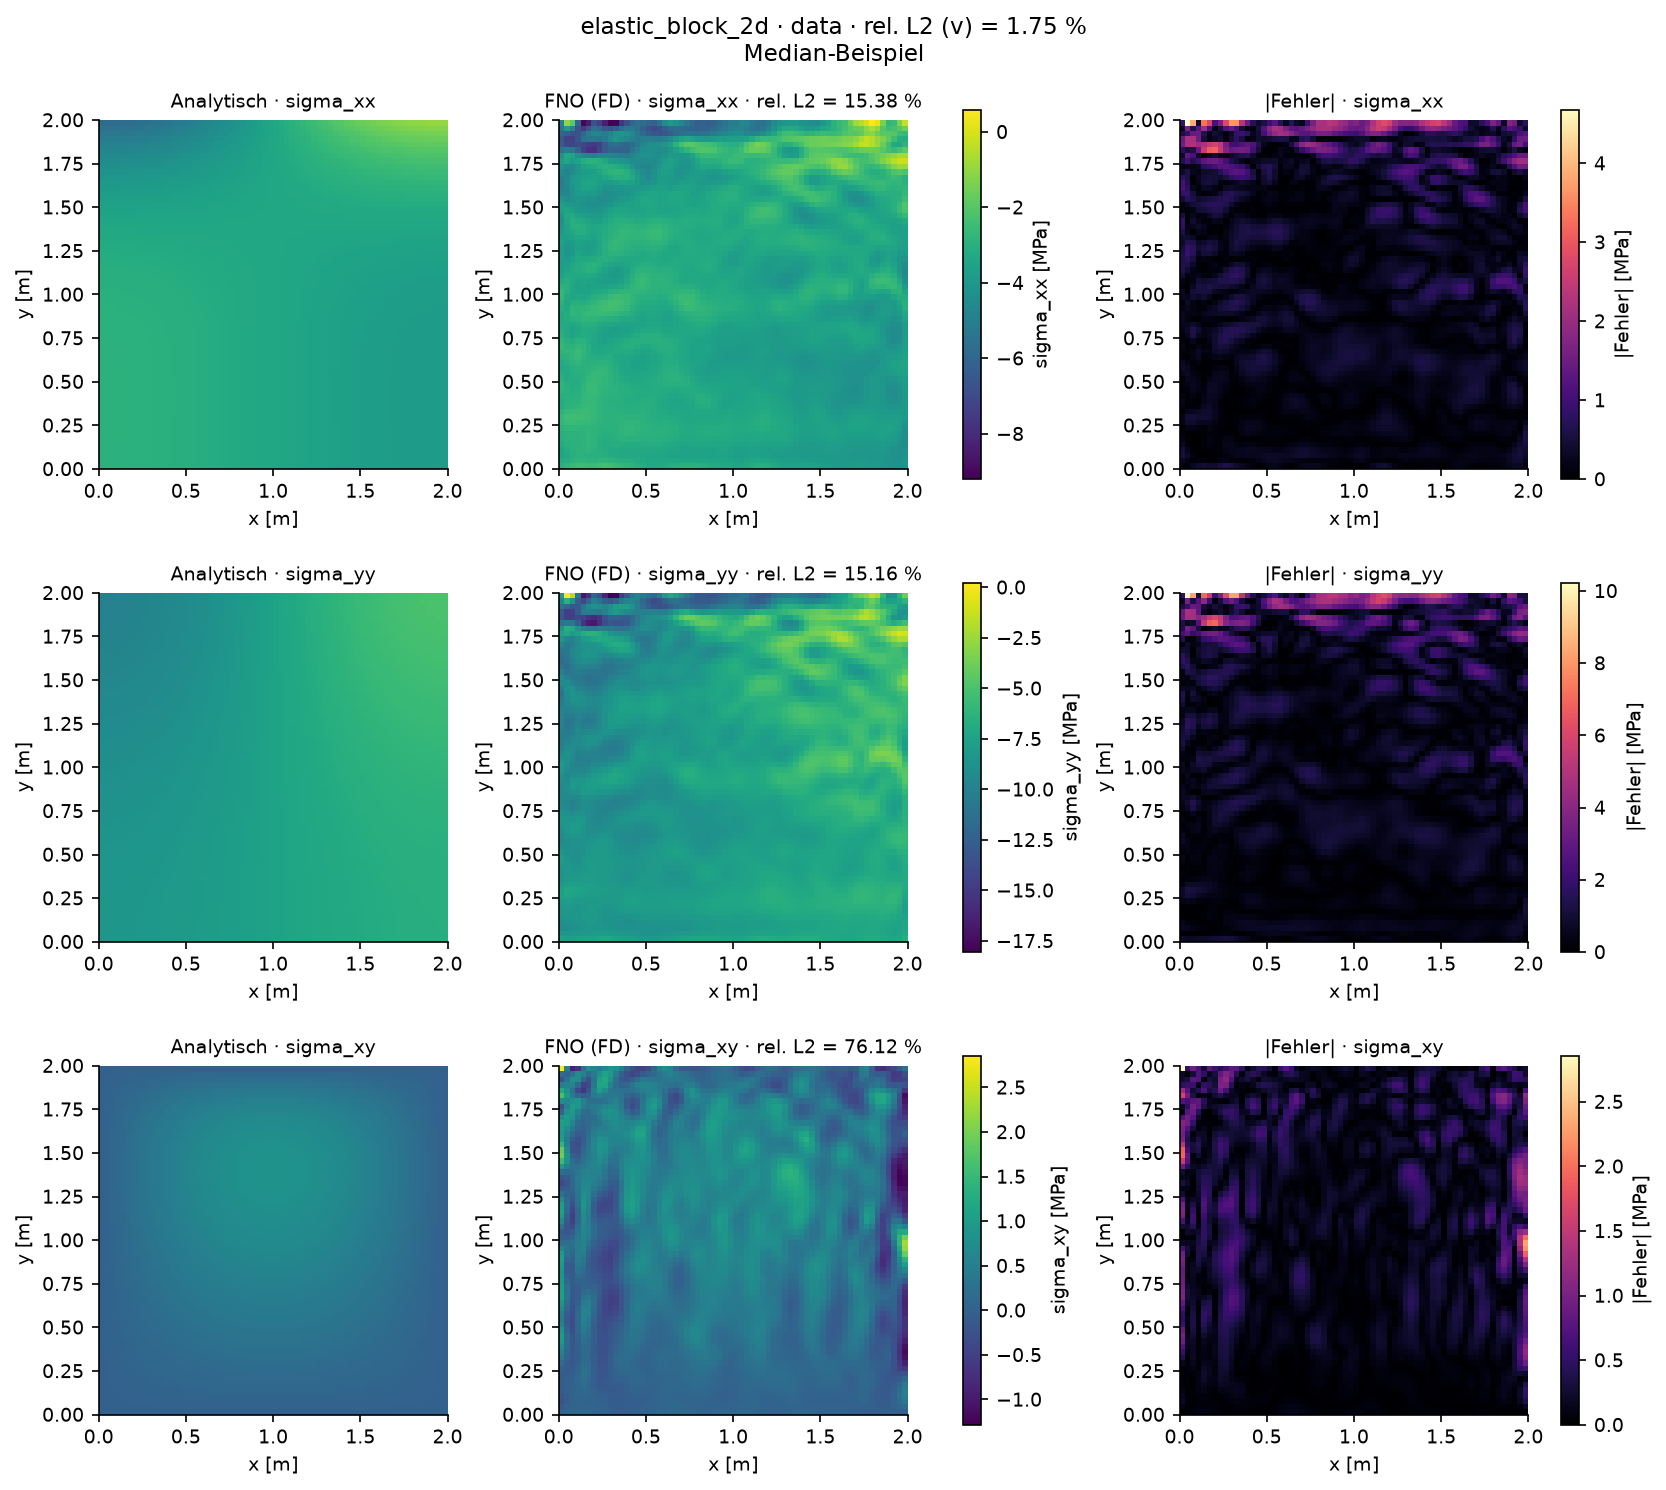


outside: load from below
  rel. L2  {'u': '118.867 %', 'v': '92.804 %'}
  bc error {'u': '0.000 %', 'v': '0.000 %'}
  EXTRAPOLATION: input[0] = -0.75 outside the trained range [0.5, 1]


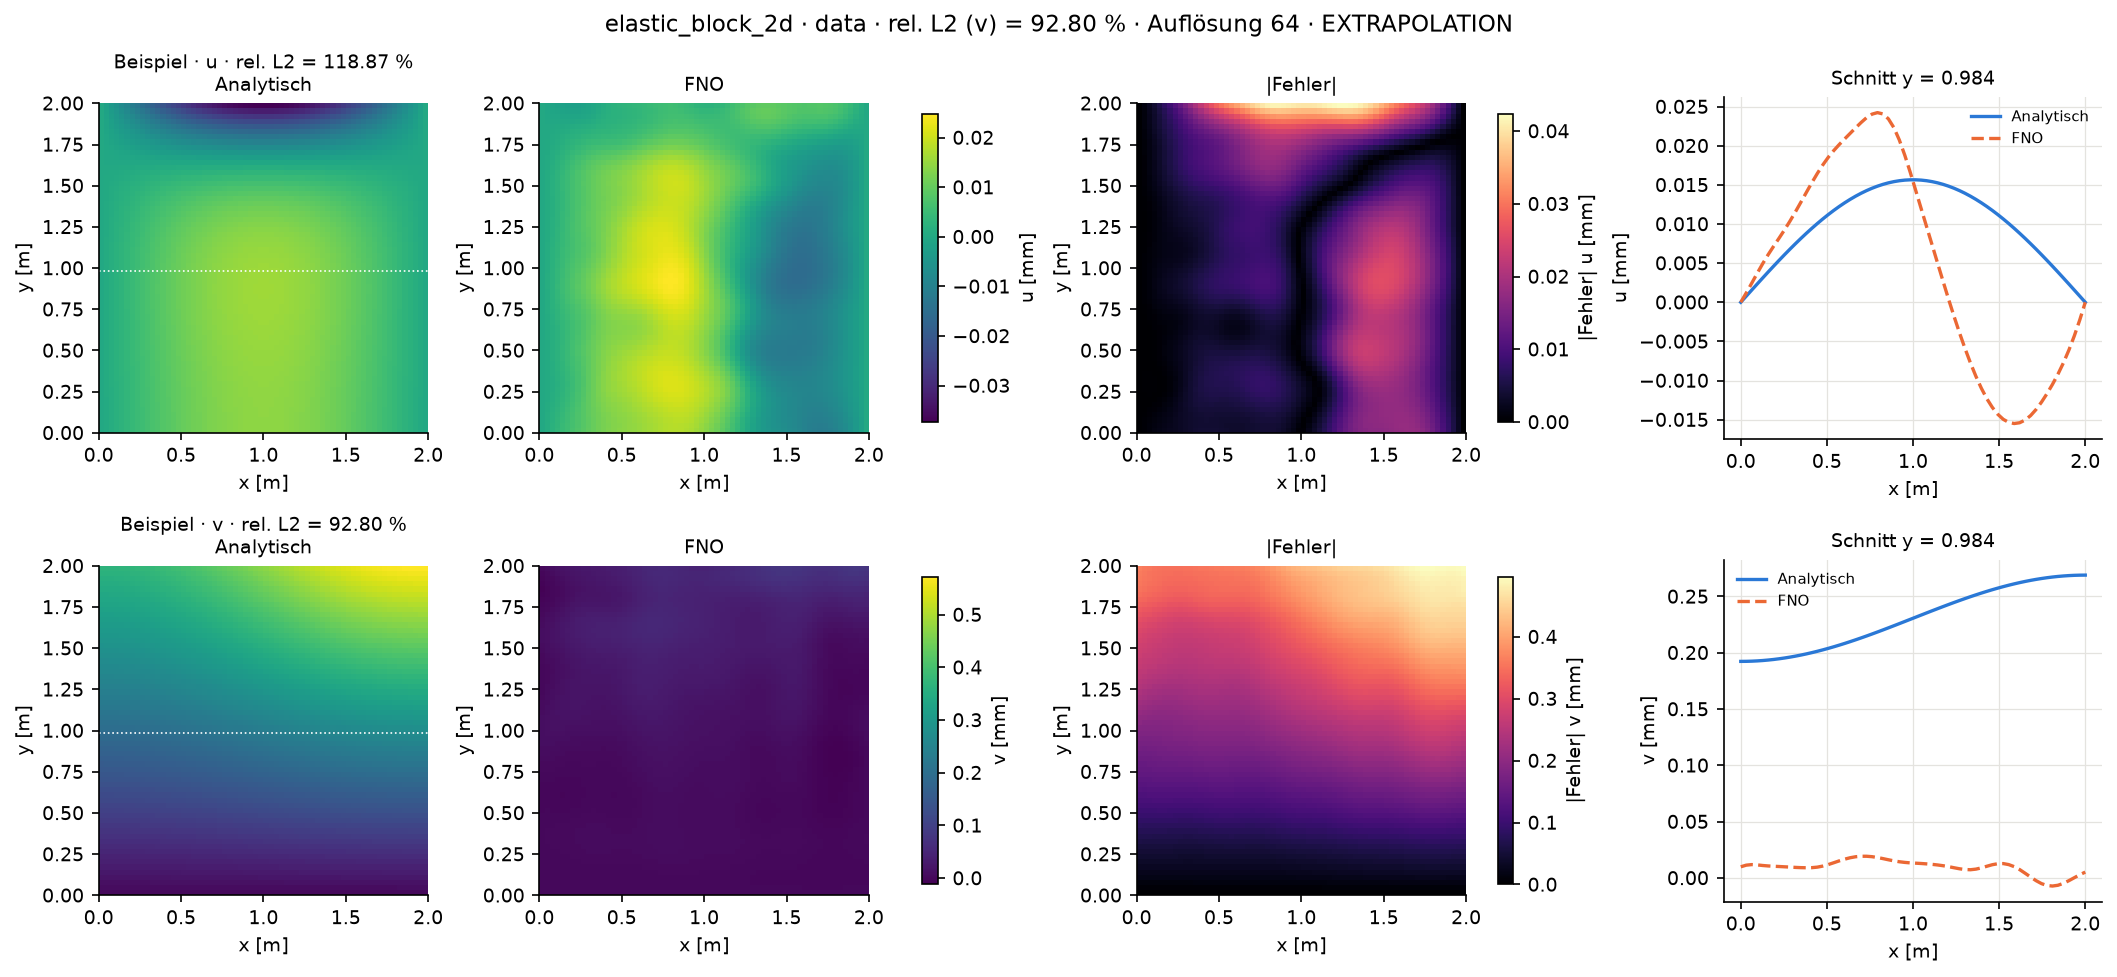

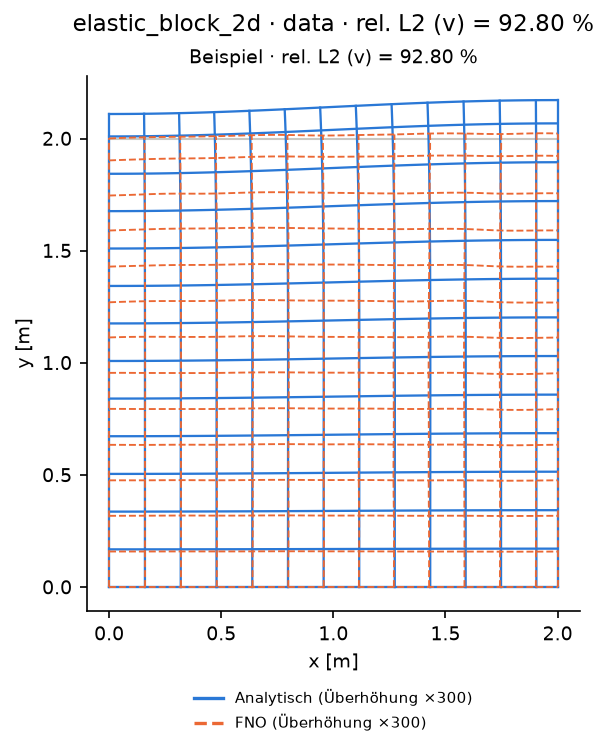

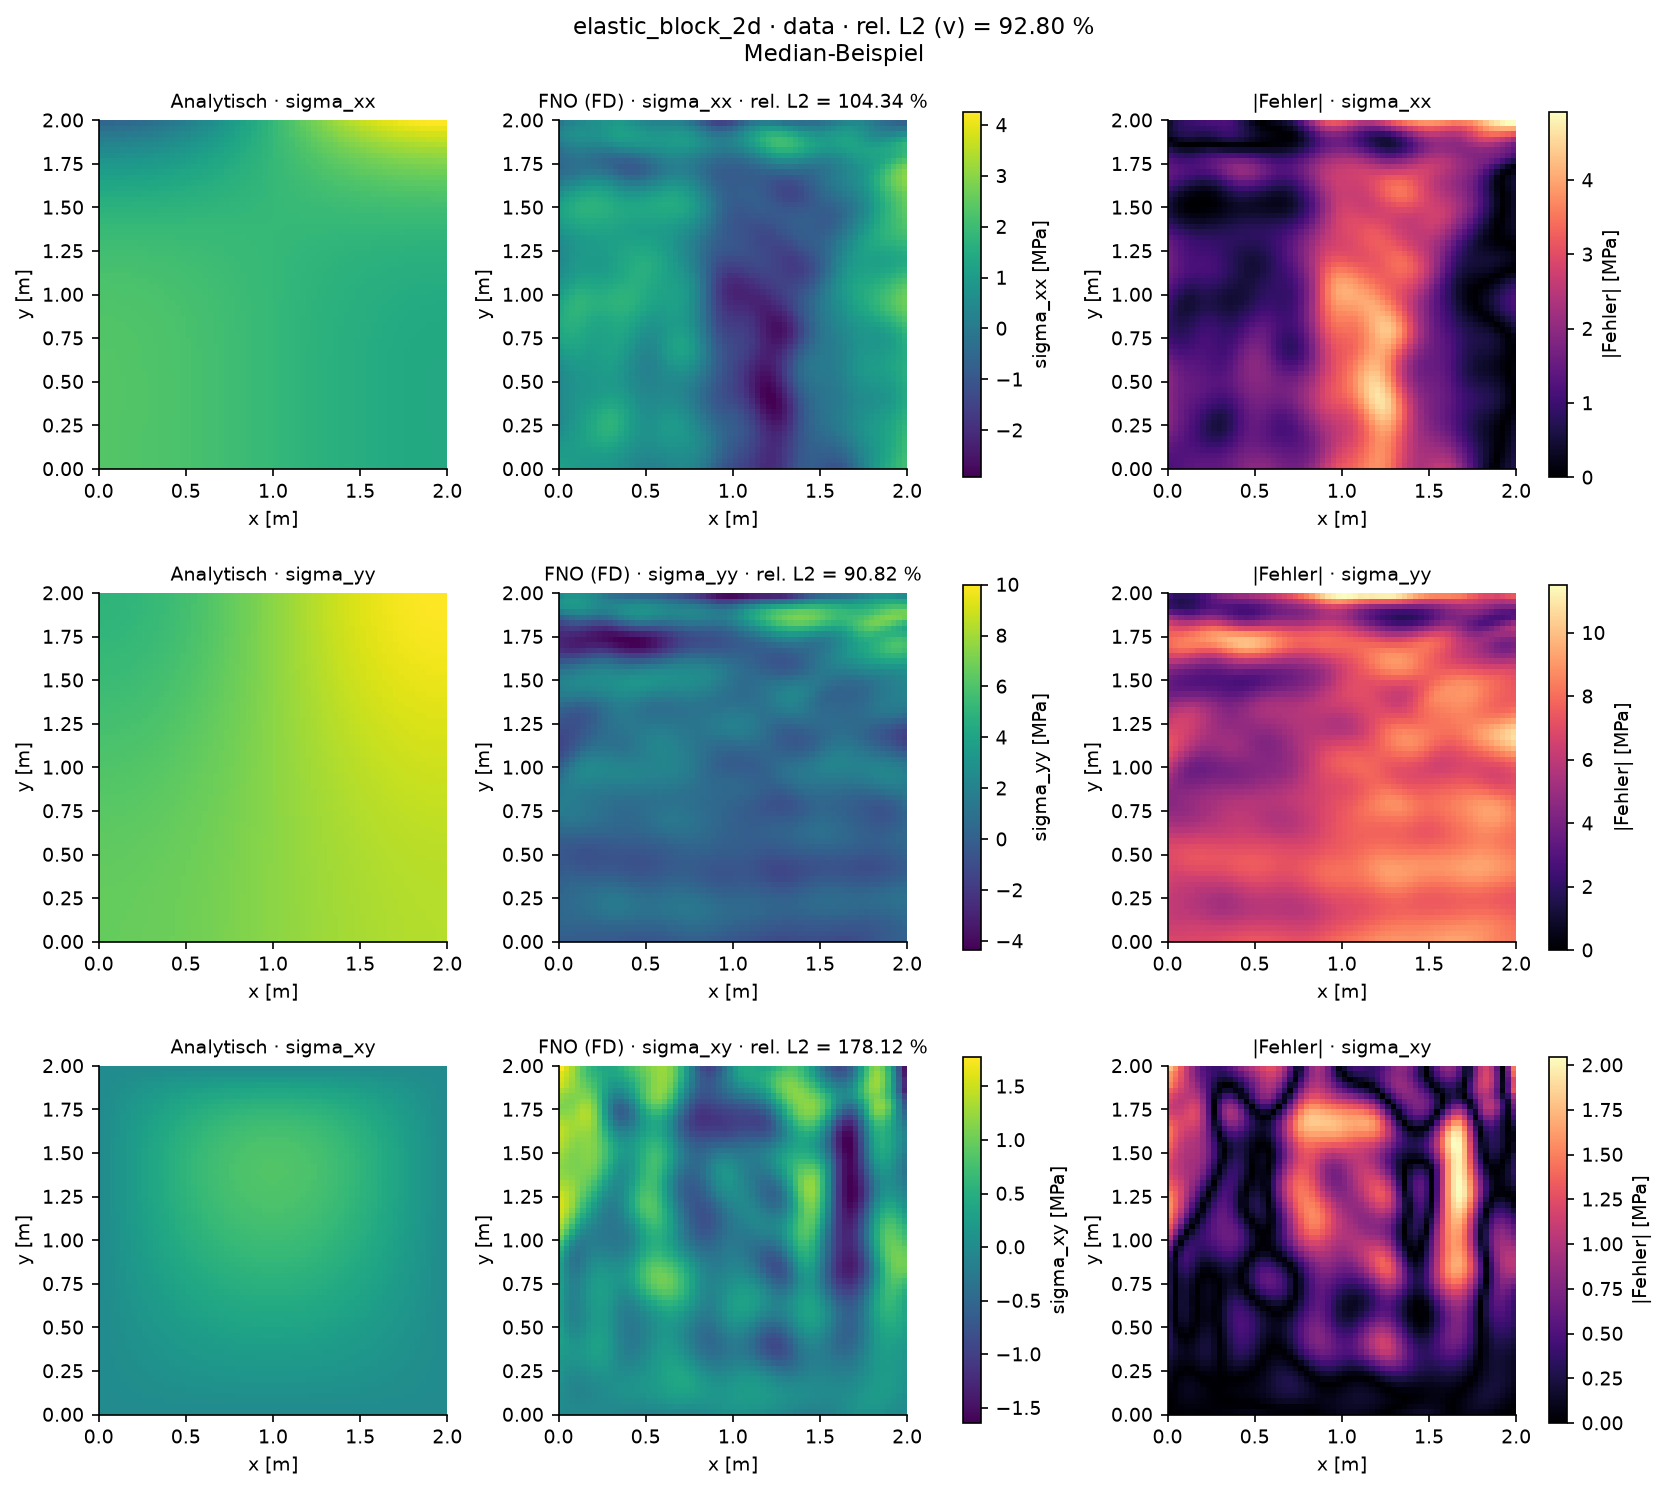

In [16]:
CASES = {
    "uniform load": [1.0, 0, 0, 0, 0, 0, 0, 0.25],
    "heavier on the left": [0.75, 0.5, 0, 0, 0, 0, 0, 0.25],
    "short wave n = 6": [0.75, 0, 0, 0, 0, 0, 0.083, 0.25],
    "all modes, nu = 0.15": [1.0, 0.5, -0.25, 0.167, -0.125, 0.1, -0.083, 0.15],
    "outside: nu = 0.45": [0.75, 0.25, 0, 0, 0, 0, 0, 0.45],
    "outside: load from below": [-0.75, 0.25, 0, 0, 0, 0, 0, 0.25],
}
compare_variants("elastic_block_2d", CASES)
try_cases("elastic_block_2d", CASES, mode="data", output_param="constrained")

### `thermoelastic_block_2d`

Heated on top, T_top(x) = t₀ + Σ tₙ cos(nπx). Input: `[t0, t1..t6, nu]`, trained t₀ ∈ [0.5, 1], tₙ ∈ [−0.5/n, 0.5/n], ν ∈ [0.15, 0.35]. Outputs T, u, v; also shows the deformed grid and the stresses. With uniform heating the exact u is 0, so its relative error means nothing, and σ_yy and σ_xy are nearly 0 in every case, so read their errors in MPa in the plot.

In [4]:
CASES = {
    "uniform heating": [1.0, 0, 0, 0, 0, 0, 0, 0.25],
    "hotter on the left": [0.75, 0.5, 0, 0, 0, 0, 0, 0.25],
    "short wave n = 6": [0.75, 0, 0, 0, 0, 0, 0.083, 0.25],
    "all modes, nu = 0.15": [1.0, 0.5, -0.25, 0.167, -0.125, 0.1, -0.083, 0.15],
    "outside: nu = 0.45": [0.75, 0.25, 0, 0, 0, 0, 0, 0.45],
    "outside: top twice as hot": [2.0, 0.5, 0, 0, 0, 0, 0, 0.25],
}
compare_variants("thermoelastic_block_2d", CASES)
try_cases("thermoelastic_block_2d", CASES, mode="data", output_param="constrained")

  case 1: uniform heating
  case 2: hotter on the left
  case 3: short wave n = 6
  case 4: all modes, nu = 0.15
  case 5: outside: nu = 0.45
  case 6: outside: top twice as hot
                                 case 1     case 2     case 3     case 4     case 5     case 6
constrained data                 0.45%      0.48%      0.43%      2.44%      0.53%*     2.14%*
constrained hybrid               4.91%      3.89%      1.09%      4.33%      3.79%*    11.86%*
constrained physics             23.94%     14.10%      7.69%     20.69%     17.95%*    46.65%*
direct data                      0.17%      0.25%      0.22%      0.98%      1.34%*     5.52%*
soft data                        0.20%      0.28%      0.24%      1.08%      0.75%*     6.76%*
soft physics                    28.20%     23.18%     18.19%     23.67%     30.66%*    42.09%*
outputs/thermoelastic_block_2d/cosine-constrained/data/2026-11-08_18-09-39
trained input ranges, low  [0.5, -0.5, -0.25, -0.167, -0.125, -0.1, -0.083, 0.15]


/home/imb-user/Documents/johannes/PINOBench/src/pino/visualization.py:480: RuntimeWarning: divide by zero encountered in scalar divide
  relative = np.linalg.norm(error) / np.linalg.norm(analytical)


<Figure size 2100x1440 with 18 Axes>

<Figure size 705x735 with 1 Axes>

<Figure size 1650x1485 with 15 Axes>


hotter on the left
  rel. L2  {'T': '0.237 %', 'u': '0.215 %', 'v': '0.485 %'}
  bc error {'T': '0.000 %', 'u': '0.000 %', 'v': '0.000 %'}


... (15 outputs left out)


outside: top twice as hot
  rel. L2  {'T': '1.730 %', 'u': '7.689 %', 'v': '2.140 %'}
  bc error {'T': '0.000 %', 'u': '0.000 %', 'v': '0.000 %'}
  EXTRAPOLATION: input[0] = 2 outside the trained range [0.5, 1]


<Figure size 2100x1440 with 18 Axes>

<Figure size 705x735 with 1 Axes>

<Figure size 1650x1485 with 15 Axes>

## Hydro

### `darcy_layered_1d`

Two layers. Input: `[k1, k2, x_s]`, trained k log-uniform in [0.1, 10], x_s ∈ [0.3, 0.7].

In [5]:
CASES = {
    "homogeneous": [1.0, 1.0, 0.5],
    "contrast 100, permeable first": [10.0, 0.1, 0.5],
    "contrast 100, tight first": [0.1, 10.0, 0.5],
    "interface far left": [10.0, 0.1, 0.3],
    "outside: k1 = 100": [100.0, 0.1, 0.5],
    "outside: x_s = 0.9": [1.0, 0.1, 0.9],
}
compare_variants("darcy_layered_1d", CASES)
try_cases("darcy_layered_1d", CASES, mode="physics", output_param="constrained")

  case 1: homogeneous
  case 2: contrast 100, permeable first
  case 3: contrast 100, tight first
  case 4: interface far left
  case 5: outside: k1 = 100
  case 6: outside: x_s = 0.9
                                 case 1     case 2     case 3     case 4     case 5     case 6
constrained data                 0.02%      0.25%      1.15%      1.16%      2.87%*    19.26%*
constrained hybrid               0.06%      0.20%      1.19%      0.63%      1.11%*    16.35%*
constrained physics              0.16%      0.63%      0.98%      0.88%      2.08%*    14.70%*
soft data                        0.17%      0.84%      1.93%      1.31%      1.28%*    18.43%*
soft hybrid                      0.04%      0.33%      0.95%      0.43%      1.55%*    12.77%*
soft physics                     0.08%      0.59%      1.94%      0.73%      2.65%*    12.76%*
outputs/darcy_layered_1d/two_layer-constrained/physics/2026-11-06_14-52-35
trained input ranges, low  [0.1, 0.1, 0.3]
                      high [9.997

<Figure size 690x525 with 2 Axes>


contrast 100, permeable first
  rel. L2  {'h': '0.628 %'}
  bc error {'h': '0.000 %'}


<Figure size 690x525 with 2 Axes>


contrast 100, tight first
  rel. L2  {'h': '0.981 %'}
  bc error {'h': '0.000 %'}


<Figure size 690x525 with 2 Axes>

... (2 outputs left out)


outside: k1 = 100
  rel. L2  {'h': '2.082 %'}
  bc error {'h': '0.000 %'}
  EXTRAPOLATION: input[0] = 100 outside the trained range [0.1, 9.997]


<Figure size 690x525 with 2 Axes>


outside: x_s = 0.9
  rel. L2  {'h': '14.704 %'}
  bc error {'h': '0.000 %'}
  EXTRAPOLATION: input[2] = 0.9 outside the trained range [0.3, 0.7]


<Figure size 690x525 with 2 Axes>

### `richards_steady_1d`

Input: `[alpha, q/Ks]`, trained α ∈ [1, 5], q/Ks ∈ [−0.9, −0.1].

In [ ]:
CASES = {
    "gentle soil": [1.0, -0.5],
    "steep soil, low flux": [5.0, -0.1],
    "steep soil, high flux": [5.0, -0.9],
    "middle of the range": [3.0, -0.5],
    "outside: alpha = 10": [10.0, -0.5],
}
compare_variants("richards_steady_1d", CASES)
try_cases("richards_steady_1d", CASES, mode="physics", output_param="constrained")

### `darcy_poisson_2d`

f = Σ a_mn sin(mπx) sin(nπy). Input: 4 × 4 matrix `a`, trained a_mn ∈ [−1, 1].

In [ ]:
CASES = {
    "mode (1, 1)": [[1, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]],
    "mode (4, 4)": [[0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 1]],
    "modes (1, 3) and (3, 1)": [[0, 0, 1, 0], [0, 0, 0, 0], [-1, 0, 0, 0], [0, 0, 0, 0]],
    "checkerboard at the limit": [[1, -1, 1, -1], [-1, 1, -1, 1], [1, -1, 1, -1], [-1, 1, -1, 1]],
    "outside: amplitude 2": [[2, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]],
}
compare_variants("darcy_poisson_2d", CASES)
try_cases("darcy_poisson_2d", CASES, mode="physics", output_param="constrained")

## Transport

### `chloride_1d`

Input: `[Cs, D]`, trained Cs ∈ [0.5, 1], D ∈ [0.2, 1].

In [ ]:
CASES = {
    "high, fast": [1.0, 1.0],
    "low, slow": [0.5, 0.2],
    "high, slow (sharpest front)": [1.0, 0.2],
    "middle of the range": [0.75, 0.6],
    "outside: D = 0.05": [0.75, 0.05],
}
compare_variants("chloride_1d", CASES)
try_cases("chloride_1d", CASES, mode="physics", output_param="constrained")

### `chloride_corner_2d`

Input: `[Cs, D]`, trained Cs ∈ [0.5, 1], D ∈ [0.4, 1]. 3D FNO, slower than the others.

In [ ]:
CASES = {
    "high, fast": [1.0, 1.0],
    "low, slow": [0.5, 0.4],
    "high, slow (sharpest front)": [1.0, 0.4],
    "middle of the range": [0.75, 0.7],
    "outside: D = 0.2": [0.75, 0.2],
}
compare_variants("chloride_corner_2d", CASES)
try_cases("chloride_corner_2d", CASES, mode="physics", output_param="constrained")